Fala, pessoal!

Essa semana vamos dar mais um passo em direção ao uso das ferramentas de ML na prática. Como muitos me relataram dificuldade com Python, vamos evoluir aos poucos com alguns problemas clássicos. Vamos explorar e preparar os dados e treinar nosso primeiro modelo deste roteiro para estimar preços de venda de imóveis, dadas suas características.

**Importante:** a ideia deste Colab é ser um estudo guiado. Tudo aqui foi pensado pra vocês irem explorando. Vou procurar explicar o porquê de cada etapa e apontar links pra quem quiser se aprofundar. Tentem entender o que está acontecendo, façam os exercícios e testem as próprias ideias.

O caminho resolvido vai até um primeiro modelo, com uma preparação simples para ele conseguir receber os dados. As consultas que eu proponho servem para vocês aprenderem a explorar e usar as ferramentas. Elas não viram automaticamente regras de limpeza ou critérios para treinar. Depois dessa referência inicial, vocês podem testar outras colunas e formas de preparar os dados, sempre comparando o resultado.

**Usem IA em último caso.** Alguns me perguntaram se ainda faz sentido aprender a programar. Minha opinião continua sendo SIM! Vocês precisam entender o que estão fazendo, explicar o código e verificar se o resultado faz sentido. Isso também vale quando usam IA.

Tentem resolver primeiro. Se forem usar IA, peçam uma dica ou uma explicação e depois tentem fazer por conta própria. O que eu quero aqui é que vocês consigam testar uma ideia, encontrar um erro e entender como corrigir. Isso faz diferença quando aparece um problema de verdade.

# Desativem as sugestões de IA do Colab

Nas configurações do Colab, abram **Assistência de IA** e desativem **Mostrar sugestões inline geradas por IA**. Assim vocês conseguem tentar escrever os trechos antes de receber uma sugestão pronta.

# 1. Entendendo o problema

Muitas vezes, a nossa essência de programador fala mais forte e a gente já quer pensar no algoritmo antes de entendermos o problema a fundo. Então a primeira etapa aqui é entender o problema e os dados que temos pra trabalhar.

Um problema pode parecer simples e ainda assim esbarrar em dados insuficientes, campos mal preenchidos ou informações que não representam o que precisamos prever. Antes de escolher uma técnica, precisamos olhar o que está disponível.

## Conhecer os dados no Kaggle

Abram a [página de House Prices no Kaggle](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/overview) e deem uma olhada na descrição e na aba **Data**. Como essa página é de uma competição, ela também apresenta regras e informações sobre a avaliação.

Façam uma leitura breve pra responder:

1. O que queremos prever?
2. Em quais unidades estão o preço e a área?
3. Quais três campos vocês imaginam que podem ajudar? Por quê?

Não precisam entender todos os campos agora. Mais adiante vou organizar o dicionário e vamos olhar amostras. Quero que vocês tenham esse primeiro contato e comecem a levantar perguntas.

O [dataset de comércio eletrônico da Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) é um exemplo de página de dados fora da área de competições. Fica como referência extra para conhecer o Kaggle.


## Dataset

Os dados são registros de vendas de imóveis de Ames, nos Estados Unidos, da base House Prices. Cada linha deste arquivo corresponde a um registro de venda de uma casa. O preço está em **dólares americanos**, e a área está em **pés quadrados**.

O CSV público tem 81 colunas e 1.460 registros. Vamos abri-lo diretamente pelo endereço na internet e selecionar dez colunas dentro do notebook. Todas as linhas e os valores originais serão mantidos, sem preenchimentos ou conversões de unidades.

Escolhemos campos que permitem discutir tamanho, cômodos, garagem, localização e tempo. É um recorte para aprender a ler a tabela, ainda não uma conclusão sobre quais informações produzem o melhor modelo.

# 2. Uma comparação rápida com Python sem Pandas

Antes de seguir, vamos olhar o que acontece na leitura de um CSV. **Importante! Essa etapa é apenas para que você veja como seria abrir e processar o csv puramente e o porque de estarmos usando pandas. Portanto, não precisa entender a fundo cada etapa a seguir.**

Usaremos `urllib` para buscar o arquivo e `csv` para ler os registros. Os dois já vêm com o Python.

Esta demonstração é só pra comparar as etapas. O ponto principal é observar o que recebemos e o que ainda precisamos preparar.

No import abaixo, `urllib.request` é o módulo e `urlretrieve` é a função que vamos usar. `from ... import ...` permite chamar essa função diretamente pelo nome. Outra forma seria importar `request` e chamar `request.urlretrieve(...)`; o que muda aqui é a forma de acessar o nome. No Colab, vocês podem passar o mouse sobre uma função para consultar seus argumentos.

In [289]:
# Pegamos urlretrieve dentro de urllib.request para chamar a função pelo próprio nome.
# Essa forma de importar muda como acessamos a função; não significa carregar só ela.
from urllib.request import urlretrieve

# Alternativamente, poderíamos usar:
# from urllib import request
# request.urlretrieve(csv_url, "houses-demo.csv")

csv_url = "https://raw.githubusercontent.com/Rswcf/houseprices_kaggle/017cd478d912a0af0b754808191dbff45478bc47/train.csv"

# Deixem o mouse sobre a função para consultar os argumentos e valores padrão.
urlretrieve(csv_url, "houses-demo.csv")

print("Arquivo baixado.")

Arquivo baixado.


### Primeiro, olhar o texto do CSV

Beleza, baixamos o arquivo. Antes de interpretar os registros, vamos mostrar as duas primeiras linhas: o cabeçalho, com os nomes das colunas, e os valores da primeira casa.

`readline()` lê uma linha do arquivo por vez. Neste CSV, cada registro tem muitos campos separados por vírgulas. O formato é útil para guardar e trocar dados, mas a linha comprida não facilita nossa leitura na tela.

In [290]:
# with fecha o arquivo ao sair do bloco, inclusive se ocorrer um erro.
with open("houses-demo.csv", encoding="utf-8", newline="") as csv_file:
    # ler a primeira linha do csv, que mostra o cabeçalho
    csv_header_text = csv_file.readline()
    # ler segunda linha, que é a primeira entrada do dataset
    first_house_text = csv_file.readline()

print(csv_header_text)

print(first_house_text)

Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice

1,60,RL,65,8450,Pave,NA,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196,Gd,TA,PC

### Interpretar os registros

Agora vamos abrir o arquivo novamente para ler desde o começo. Vamos separar duas operações: criar um leitor e percorrer os registros para guardá-los.

`csv.DictReader(csv_file)` usa o cabeçalho para associar os nomes das colunas aos valores de cada registro. Vamos chamar esse leitor de `csv_reader`. Ele permite ler os registros conforme são pedidos; essa linha ainda não carrega todos eles.

Na linha seguinte, `list(csv_reader)` percorre o leitor até o fim e reúne os registros na lista `house_records`. Fazemos isso dentro do `with`, enquanto o arquivo está aberto.

O `with` mantém o arquivo aberto durante o bloco recuado e garante seu fechamento ao sair dele, mesmo se ocorrer um erro; assim, não precisamos chamar `close()` manualmente.

In [291]:
import csv

with open("houses-demo.csv") as csv_file:
    # O leitor interpreta cada linha usando os nomes do cabeçalho.
    csv_reader = csv.DictReader(csv_file)

    # Consumimos o leitor enquanto o arquivo está aberto e guardamos os registros.
    house_records = list(csv_reader)

print("Registros guardados:", len(house_records))

Registros guardados: 1460


### Mostrar um registro sem formatar

Agora `house_records` é uma lista de registros na memória. O arquivo já foi fechado, mas podemos continuar usando essa lista.

Vamos mostrar só a primeira casa, usando `[0]`. Ela ainda tem os 81 campos. A saída abaixo é a representação de um dicionário do Python, com nomes e valores; já interpretamos o CSV, então não estamos mais olhando o texto original do arquivo.

In [292]:
print(house_records[0])

{'Id': '1', 'MSSubClass': '60', 'MSZoning': 'RL', 'LotFrontage': '65', 'LotArea': '8450', 'Street': 'Pave', 'Alley': 'NA', 'LotShape': 'Reg', 'LandContour': 'Lvl', 'Utilities': 'AllPub', 'LotConfig': 'Inside', 'LandSlope': 'Gtl', 'Neighborhood': 'CollgCr', 'Condition1': 'Norm', 'Condition2': 'Norm', 'BldgType': '1Fam', 'HouseStyle': '2Story', 'OverallQual': '7', 'OverallCond': '5', 'YearBuilt': '2003', 'YearRemodAdd': '2003', 'RoofStyle': 'Gable', 'RoofMatl': 'CompShg', 'Exterior1st': 'VinylSd', 'Exterior2nd': 'VinylSd', 'MasVnrType': 'BrkFace', 'MasVnrArea': '196', 'ExterQual': 'Gd', 'ExterCond': 'TA', 'Foundation': 'PConc', 'BsmtQual': 'Gd', 'BsmtCond': 'TA', 'BsmtExposure': 'No', 'BsmtFinType1': 'GLQ', 'BsmtFinSF1': '706', 'BsmtFinType2': 'Unf', 'BsmtFinSF2': '0', 'BsmtUnfSF': '150', 'TotalBsmtSF': '856', 'Heating': 'GasA', 'HeatingQC': 'Ex', 'CentralAir': 'Y', 'Electrical': 'SBrkr', '1stFlrSF': '856', '2ndFlrSF': '854', 'LowQualFinSF': '0', 'GrLivArea': '1710', 'BsmtFullBath': '1',

### Organizar a apresentação com pprint

Fica difícil de acompanhar, né? Os dados já estão organizados por nome de campo, mas o `print` mostra tudo junto. Vamos usar `pprint`, da biblioteca padrão, para distribuir os pares de nome e valor em linhas mais fáceis de ler.

Vamos mostrar a mesma casa. `sort_dicts=False` mantém a ordem original dos campos. A formatação muda a apresentação, sem alterar o registro.

In [293]:
from pprint import pprint

pprint(house_records[0], sort_dicts=False)

{'Id': '1',
 'MSSubClass': '60',
 'MSZoning': 'RL',
 'LotFrontage': '65',
 'LotArea': '8450',
 'Street': 'Pave',
 'Alley': 'NA',
 'LotShape': 'Reg',
 'LandContour': 'Lvl',
 'Utilities': 'AllPub',
 'LotConfig': 'Inside',
 'LandSlope': 'Gtl',
 'Neighborhood': 'CollgCr',
 'Condition1': 'Norm',
 'Condition2': 'Norm',
 'BldgType': '1Fam',
 'HouseStyle': '2Story',
 'OverallQual': '7',
 'OverallCond': '5',
 'YearBuilt': '2003',
 'YearRemodAdd': '2003',
 'RoofStyle': 'Gable',
 'RoofMatl': 'CompShg',
 'Exterior1st': 'VinylSd',
 'Exterior2nd': 'VinylSd',
 'MasVnrType': 'BrkFace',
 'MasVnrArea': '196',
 'ExterQual': 'Gd',
 'ExterCond': 'TA',
 'Foundation': 'PConc',
 'BsmtQual': 'Gd',
 'BsmtCond': 'TA',
 'BsmtExposure': 'No',
 'BsmtFinType1': 'GLQ',
 'BsmtFinSF1': '706',
 'BsmtFinType2': 'Unf',
 'BsmtFinSF2': '0',
 'BsmtUnfSF': '150',
 'TotalBsmtSF': '856',
 'Heating': 'GasA',
 'HeatingQC': 'Ex',
 'CentralAir': 'Y',
 'Electrical': 'SBrkr',
 '1stFlrSF': '856',
 '2ndFlrSF': '854',
 'LowQualFinSF': '

### Reduzir a quantidade de informação

Melhor, né? Mas ainda são 81 campos para uma única casa. Formatar ajuda, só que a quantidade de informação continua grande.

Vamos preparar uma amostra com quatro campos: identificação, preço, área e bairro. `first_house` pega o primeiro registro, `preview_house` guarda os campos escolhidos e `[preview_house]` coloca essa casa em uma lista. O recorte é só para apresentação; `house_records` continua inteiro.

In [294]:
first_house = house_records[0]

# Montamos uma amostra com apenas quatro campos do primeiro registro.
preview_house = {
    "Id": first_house["Id"],
    "SalePrice": first_house["SalePrice"],
    "GrLivArea": first_house["GrLivArea"],
    "Neighborhood": first_house["Neighborhood"],
}

preview_records = [preview_house]

pprint(preview_records, sort_dicts=False)

[{'Id': '1',
  'SalePrice': '208500',
  'GrLivArea': '1710',
  'Neighborhood': 'CollgCr'}]


Agora ficou mais fácil observar a casa. Na saída acima, os colchetes `[...]` delimitam a lista, e as chaves `{...}` delimitam o registro com pares de nome e valor. Para selecionar o primeiro registro dessa lista, usamos `house_records[0]`. As aspas em valores como `'208500'` mostram que eles ainda são textos.

<details><summary>Consulta opcional: converter um preço em número</summary>

Para fazer contas com esse preço, podemos converter o texto com `float`. Separamos primeiro o campo e depois a conversão:

```python
first_price_text = first_house["SalePrice"]
first_price = float(first_price_text)

print(first_price)
print(type(first_price))
```

</details>

### Seguir para a análise

Vimos o texto do arquivo, interpretamos os registros, melhoramos a formatação e escolhemos uma amostra menor. São operações diferentes. O `pprint` ajuda a apresentar os registros, mas não escolhe por nós quais informações queremos observar.

Com a biblioteca padrão conseguimos fazer esse trabalho. Para continuar, vamos querer selecionar colunas, filtrar, agrupar e calcular resumos. O Pandas oferece essas operações em uma estrutura de tabela e deixa esses recortes mais diretos.

Vamos seguir com ele.

<details><summary>Consulta opcional: outras formas de buscar o CSV</summary>

- [urllib](https://docs.python.org/3/library/urllib.request.html#urllib.request.urlretrieve) e [csv](https://docs.python.org/3/library/csv.html): biblioteca padrão, como no exemplo.
- [wget](https://www.gnu.org/software/wget/manual/html_node/Download-Options): programa externo que baixa o arquivo. No Colab, `!wget -q -O houses-demo.csv "{csv_url}"` executa esse comando, se estiver disponível. Depois ainda é preciso interpretar o CSV.
- [Requests](https://requests.readthedocs.io/en/latest/user/quickstart/): biblioteca adicional para requisições HTTP. Pode ajudar quando precisamos controlar cabeçalhos ou autenticação; o conteúdo ainda precisa de um leitor.
- [pd.read_csv(URL)](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html): busca o CSV público e cria um DataFrame diretamente. É o caminho que vamos usar na análise.

</details>

## Continuar a análise com Pandas

Vamos usar o Pandas agora e comparar com o que fizemos usando a biblioteca padrão do Python. A ideia é ver como ele facilita a leitura e a exploração dos dados.

**Pandas** é uma biblioteca de Python para trabalhar com dados em tabelas. Um **DataFrame** é uma estrutura de dados com linhas e colunas, que vamos usar para guardar e analisar essa tabela na memória.

Em `import pandas as pd`, importamos a biblioteca e usamos `as` para dar a ela um **alias**, ou seja, um apelido. Nesse código, o apelido é `pd`. Poderíamos escolher outro nome válido, mas `pd` é uma **convenção**: é o nome normalmente usado na documentação e nos exemplos. Seguir esse padrão facilita entender e compartilhar o código.

Depois, `pd.read_csv("URL")` lê o CSV diretamente da internet e cria um DataFrame. `houses = ...` guarda uma referência a essa tabela na variável `houses`. Vamos mostrar como ela aparece no Colab e usar essa estrutura no restante do estudo.

Também guardamos a referência à tabela completa com o nome `all_houses`. Essa atribuição dá outro nome à mesma tabela; ainda não cria uma cópia. Ela permite manter a base completa acessível quando prepararmos o recorte do estudo.

In [295]:
import pandas as pd

# Pandas busca o CSV na URL e organiza os dados em um DataFrame.
houses = pd.read_csv("https://raw.githubusercontent.com/Rswcf/houseprices_kaggle/017cd478d912a0af0b754808191dbff45478bc47/train.csv")

# Mantemos outro nome para acessar a tabela completa depois do recorte.
all_houses = houses

houses

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


### Como vamos mostrar as tabelas

Reparem que a célula terminou com `houses`. O Colab exibe o resultado da última expressão e, quando esse resultado é um DataFrame, apresenta uma tabela formatada. `print(houses)` produz uma representação em texto.

Se precisarmos mostrar uma tabela antes do fim de uma célula, podemos chamar `display`. Ela é uma função do IPython, o ambiente usado pelo notebook, e preserva a apresentação da tabela. O exemplo abaixo mostra essa alternativa.

Neste estudo, vamos priorizar uma saída por célula. Quando a tabela puder ficar no fim, basta deixar o nome dela ou a expressão que queremos ver. A visualização pode abreviar linhas e colunas sem retirar esses dados do DataFrame.

In [296]:
from IPython.display import display

display(houses)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


Daqui pra frente vamos usar principalmente a exibição automática, deixando cada tabela na própria célula. Assim fica mais fácil relacionar a operação com o resultado. `display` fica disponível para quando houver necessidade de exibir um objeto no meio de outro processamento.

### Uma coluna ou várias?

Vamos começar selecionando apenas o preço. `all_houses["SalePrice"]` recebe um nome de coluna e devolve uma **Series**, uma estrutura de uma dimensão. A gente continua com os valores e o índice dos registros.

In [297]:
all_houses["SalePrice"]

,SalePrice
0,208500
1,181500
2,223500
3,140000
4,250000
...,...
1455,175000
1456,210000
1457,266500
1458,142125


Para selecionar várias colunas, passamos uma **lista** de nomes. Em `all_houses[["GrLivArea", "SalePrice"]]`, os colchetes de dentro criam a lista e os de fora fazem a seleção no DataFrame.

O resultado continua sendo um DataFrame. Se quisermos uma tabela com uma única coluna, também podemos passar uma lista com um item, como `all_houses[["SalePrice"]]`. E aí, vocês conseguem perceber a diferença entre selecionar um nome e passar uma lista de nomes?

In [298]:
all_houses[["GrLivArea", "SalePrice"]]

,GrLivArea,SalePrice
0,1710,208500
1,1262,181500
2,1786,223500
3,1717,140000
4,2198,250000
...,...,...
1455,1647,175000
1456,2073,210000
1457,2340,266500
1458,1078,142125


### Selecionar as colunas do estudo, passo a passo

A base tem 81 colunas. Vamos começar com dez campos para acompanhar o estudo: identificação, preço, área, quartos, banheiros, vagas, bairro e anos. Os nomes originais estão na lista abaixo e serão explicados no dicionário da próxima seção. Eu escolhi esse recorte para começar com campos de significado mais próximo do problema e reduzir a quantidade de informação ao mesmo tempo. Isso não significa que sejam as melhores entradas para o modelo nem que as outras colunas não sirvam. A base completa continua em `all_houses` para vocês testarem outras escolhas depois.

**1. Criar a lista de nomes**

`study_columns` guarda uma lista de textos com os nomes das colunas que queremos. Os colchetes criam essa lista, e as vírgulas separam seus itens. Nesta etapa, ainda não selecionamos nenhum dado da tabela.

In [299]:
# Nesta etapa criamos apenas a lista de nomes, sem selecionar os dados.
study_columns = [
    "Id",
    "SalePrice",
    "GrLivArea",
    "BedroomAbvGr",
    "FullBath",
    "HalfBath",
    "GarageCars",
    "Neighborhood",
    "YearBuilt",
    "YrSold",
]

**2. Selecionar essas colunas na tabela completa**

`all_houses[study_columns]` usa a lista de nomes para selecionar as colunas do DataFrame. Aqui os colchetes fazem uma seleção na tabela, em vez de criar outra lista de textos.

Guardamos o resultado em `selected_houses`: outro DataFrame, com as mesmas 1.460 linhas e apenas as dez colunas escolhidas, na ordem da lista. `all_houses` continua disponível com as 81 colunas. Vamos mostrar o recorte para conferir como ficou.

In [300]:
# A lista informa quais colunas queremos, mantendo todas as linhas.
selected_houses = all_houses[study_columns]

selected_houses

,Id,SalePrice,GrLivArea,BedroomAbvGr,FullBath,HalfBath,GarageCars,Neighborhood,YearBuilt,YrSold
0,1,208500,1710,3,2,1,2,CollgCr,2003,2008
1,2,181500,1262,3,2,0,2,Veenker,1976,2007
2,3,223500,1786,3,2,1,2,CollgCr,2001,2008
3,4,140000,1717,3,1,0,3,Crawfor,1915,2006
4,5,250000,2198,4,2,1,3,NoRidge,2000,2008
...,...,...,...,...,...,...,...,...,...,...
1455,1456,175000,1647,3,2,1,2,Gilbert,1999,2007
1456,1457,210000,2073,3,2,0,2,NWAmes,1978,2010
1457,1458,266500,2340,4,2,0,1,Crawfor,1941,2010
1458,1459,142125,1078,2,1,0,1,NAmes,1950,2010


**3. Criar uma cópia para continuar o estudo**

Se fizéssemos apenas `houses = selected_houses`, os dois nomes apontariam para o mesmo DataFrame. `.copy()` cria outro DataFrame com uma cópia dos dados do recorte. Vamos usar essa cópia como `houses` nas próximas etapas.

Assim, podemos alterar valores na tabela de trabalho sem alterar `selected_houses`. A tabela completa continua acessível como `all_houses`. Não estamos copiando o arquivo CSV no disco: a cópia é dos dados na memória.

Para só visualizar o recorte, `.copy()` não é obrigatório. Aqui usamos a cópia explícita para separar a tabela de trabalho; isso também consome memória. Não é correto presumir que toda seleção sem `.copy()` modifica a tabela original: o Pandas também oferece mecanismos de isolamento, que variam conforme a operação e a versão.

[Referência sobre cópias de DataFrames](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.copy.html).

In [301]:
# Criamos a tabela de trabalho com uma cópia dos dados selecionados.
houses = selected_houses.copy()

## 3. Conferir algumas linhas

`head(5)` mostra os cinco primeiros registros. Vamos usar essa amostra para conferir nomes, valores e a organização da tabela. Ela ajuda a enxergar o formato dos dados, mas não descreve a distribuição da base inteira.

In [302]:
houses.head(5)

,Id,SalePrice,GrLivArea,BedroomAbvGr,FullBath,HalfBath,GarageCars,Neighborhood,YearBuilt,YrSold
0,1,208500,1710,3,2,1,2,CollgCr,2003,2008
1,2,181500,1262,3,2,0,2,Veenker,1976,2007
2,3,223500,1786,3,2,1,2,CollgCr,2001,2008
3,4,140000,1717,3,1,0,3,Crawfor,1915,2006
4,5,250000,2198,4,2,1,3,NoRidge,2000,2008


### Como ler essa saída

Cada linha mostrada continua sendo um registro de venda. Os títulos são os nomes das colunas.

Os números à esquerda, normalmente 0, 1, 2, 3 e 4, são o **índice** que o Pandas está usando para localizar linhas. A coluna `Id` pertence ao arquivo e tem outro papel: identificar o registro. Índice e `Id` não são a mesma coisa.

Se aparecer `...`, a apresentação foi abreviada para caber na saída. Isso não significa que as colunas foram apagadas. Logo vamos mostrar um recorte menor.

**Cuidado:** as primeiras cinco linhas ajudam a entender o formato. Elas não bastam para dizer como são todas as casas da base.

### Selecionar um recorte para trabalhar

Agora façam vocês. Criem uma lista `property_columns` com identificação, área habitável, quartos acima do solo, vagas e preço. Consultem os nomes no dicionário quando precisarem.

Usem essa lista para selecionar as colunas de `all_houses`, guardem o recorte em `property_selection` e criem uma cópia em `property_study`. Deixem `property_study` no fim da célula para mostrar a tabela.

A tabela completa deve continuar acessível com as 81 colunas. Confiram se o recorte manteve os mesmos registros e a ordem dos campos escolhidos. Essa seleção é para praticar a consulta; ela não define as entradas do modelo.

In [303]:
# Write your code here.
property_columns = [
    "Id",
    "SalePrice",
    "GrLivArea",
    "BedroomAbvGr",
    "GarageCars",
]

property_selection = all_houses[property_columns]
property_study = property_selection.copy()

property_study

,Id,SalePrice,GrLivArea,BedroomAbvGr,GarageCars
0,1,208500,1710,3,2
1,2,181500,1262,3,2
2,3,223500,1786,3,2
3,4,140000,1717,3,3
4,5,250000,2198,4,3
...,...,...,...,...,...
1455,1456,175000,1647,3,2
1456,1457,210000,2073,3,2
1457,1458,266500,2340,4,1
1458,1459,142125,1078,2,1


## 4. Conferir as dimensões

`shape` informa quantas linhas e colunas temos, nessa ordem. E aí, o recorte mudou a quantidade de casas ou só as informações disponíveis sobre elas?

`shape` é uma propriedade do DataFrame; por isso não colocamos parênteses depois dela. Vamos conferir as dimensões da tabela de trabalho.

In [304]:
houses.shape

(1460, 10)

## 5. O que significa cada campo?

Antes de calcular qualquer coisa, precisamos saber o que estamos medindo. Os nomes originais foram mantidos para podermos consultar a documentação da base.

| Coluna | O que significa | Cuidado ao interpretar |
|---|---|---|
| `Id` | Identificador do registro | Um número maior não significa uma casa melhor. |
| `SalePrice` | Preço de venda, em dólares americanos | É a informação que queremos prever mais adiante. |
| `GrLivArea` | Área habitável acima do solo, em pés quadrados | Não é a área do terreno nem inclui a área do porão. |
| `BedroomAbvGr` | Quantidade de quartos acima do solo | Não inclui quartos no porão e não informa quais seriam suítes. |
| `FullBath` | Quantidade de banheiros completos acima do solo | Não informa se o banheiro está ligado a um quarto. |
| `HalfBath` | Quantidade de lavabos ou banheiros parciais acima do solo | Não deve ser confundida com `FullBath`. |
| `GarageCars` | Capacidade da garagem em número de carros | Não é a quantidade de carros do morador. |
| `Neighborhood` | Código da região ou bairro dentro de Ames | É uma categoria; não existe uma ordem numérica natural entre bairros. |
| `YearBuilt` | Ano da construção original | Não é a idade da casa; para idade precisamos de uma data de referência. |
| `YrSold` | Ano da venda | Pode servir de referência para pensar na idade na época da venda. |

**Por que esses cuidados importam?** Uma conta pode executar sem erros e ainda responder à pergunta errada se interpretarmos mal o campo. Esta base, por exemplo, não permite contar suítes diretamente.

## 6. Consultar casas com uma condição

Pra praticar filtros, vou propor uma consulta: **quais casas têm garagem com capacidade para pelo menos dois carros?** O limite de dois faz parte deste exemplo. Poderíamos fazer outra pergunta, como procurar casas sem garagem ou com capacidade para três carros.

Essa consulta não é uma etapa obrigatória de limpeza e não define quais casas vamos usar para treinar. As casas que não atendem à condição continuam na base `houses`. Os recortes deste exemplo ficam em outras variáveis.

Vamos separar o que acontece. Primeiro pegamos a coluna `GarageCars` e mostramos dez registros. Reparem no índice à esquerda: ele identifica a linha de cada valor.

In [305]:
garage_capacity = houses["GarageCars"]

garage_capacity.head(10)

,GarageCars
0,2
1,2
2,2
3,3
4,3
5,2
6,2
7,2
8,2
9,1


### Comparar cada valor com a condição

Agora fazemos `garage_capacity >= 2`. O Pandas aplica essa comparação a cada valor da coluna e devolve uma **Series de booleanos**, que vamos chamar de `garage_mask`.

Cada linha recebe `True` quando sua capacidade é maior ou igual a dois e `False` quando não atende à condição. O índice continua sendo o mesmo. Ainda não filtramos nenhuma casa: só calculamos quais atendem à condição.

In [306]:
# A comparação produz um True ou False para cada linha, sem filtrar ainda.
garage_mask = houses["GarageCars"] >= 2

garage_mask.head(10)

,GarageCars
0,True
1,True
2,True
3,True
4,True
5,True
6,True
7,True
8,True
9,False


### Conferir o que cada booleano representa

Vamos colocar o resultado ao lado da capacidade da garagem em uma tabela auxiliar. Assim dá para conferir a relação: o `True` ou `False` responde à pergunta sobre a **casa daquela linha**.

Aqui a máscara foi calculada para as linhas: ela indica quais registros entram no resultado. As informações originais continuam em `houses`; `KeepRow` existe só nesta tabela de conferência.

In [307]:
garage_check = houses[["Id", "GarageCars"]].copy()

garage_check["KeepRow"] = garage_mask

garage_check.head(10)

,Id,GarageCars,KeepRow
0,1,2,True
1,2,2,True
2,3,2,True
3,4,3,True
4,5,3,True
5,6,2,True
6,7,2,True
7,8,2,True
8,9,2,True
9,10,1,False


### Usar `.loc` para selecionar as linhas

O `.loc` é um **indexador** do DataFrame: usamos essa ferramenta para selecionar linhas e colunas por rótulos ou por uma condição booleana. Ele usa colchetes, como em `houses.loc[garage_mask]`, em vez de parênteses.

A forma geral é `houses.loc[row_selection, column_selection]`: antes da vírgula escolhemos as linhas; depois, as colunas. Se deixarmos só a seleção de linhas, todas as colunas são mantidas.

Aqui passamos a máscara que acabamos de conferir. O Pandas alinha seu índice às linhas e mantém as marcadas com `True`. Guardamos a consulta em `garage_rows`, sem retirar registros de `houses`. Comparem os índices com a tabela anterior: quais linhas deixaram de aparecer?

In [308]:
# Agora loc usa a máscara para manter somente as linhas marcadas com True.
garage_rows = houses.loc[garage_mask]

garage_rows.head(10)

,Id,SalePrice,GrLivArea,BedroomAbvGr,FullBath,HalfBath,GarageCars,Neighborhood,YearBuilt,YrSold
0,1,208500,1710,3,2,1,2,CollgCr,2003,2008
1,2,181500,1262,3,2,0,2,Veenker,1976,2007
2,3,223500,1786,3,2,1,2,CollgCr,2001,2008
3,4,140000,1717,3,1,0,3,Crawfor,1915,2006
4,5,250000,2198,4,2,1,3,NoRidge,2000,2008
5,6,143000,1362,1,1,1,2,Mitchel,1993,2009
6,7,307000,1694,3,2,0,2,Somerst,2004,2007
7,8,200000,2090,3,2,1,2,NWAmes,1973,2009
8,9,129900,1774,2,2,0,2,OldTown,1931,2008
11,12,345000,2324,4,3,0,3,NridgHt,2005,2006


### Escolher as colunas que queremos mostrar

As casas já foram filtradas. Agora fazemos uma seleção de colunas como a que vimos antes: a lista `columns` define quais campos queremos observar, e `garage_rows[columns]` monta esse recorte.

O filtro escolheu linhas; a lista escolhe colunas. A base `houses` continua inteira.

In [309]:
columns = [
    "Id",
    "GarageCars",
    "GrLivArea",
    "SalePrice",
]

garage_sample = garage_rows[columns]

garage_sample.head(10)

,Id,GarageCars,GrLivArea,SalePrice
0,1,2,1710,208500
1,2,2,1262,181500
2,3,2,1786,223500
3,4,3,1717,140000
4,5,3,2198,250000
5,6,2,1362,143000
6,7,2,1694,307000
7,8,2,2090,200000
8,9,2,1774,129900
11,12,3,2324,345000


Depois de separar as operações, podemos combinar tudo em `houses.loc[garage_mask, columns]`. Isso produz o mesmo recorte que acabamos de construir.

Também existe a forma `houses[garage_mask]` para filtrar linhas. Estamos usando `.loc` para explicitar as duas seleções e poder indicar linhas e colunas juntas.

<details><summary>Outras formas de usar .loc</summary>

| Exemplo | O que seleciona |
|---|---|
| `houses.loc[garage_mask]` | Linhas marcadas como True, todas as colunas |
| `houses.loc[garage_mask, ["Id", "SalePrice"]]` | Linhas True e duas colunas |
| `houses.loc[:, ["Id", "SalePrice"]]` | Todas as linhas e duas colunas; `:` significa todas |
| `houses.loc[[0, 9], ["Id", "SalePrice"]]` | Linhas de rótulos 0 e 9 e duas colunas |
| `houses.loc[0:4, ["Id", "SalePrice"]]` | Intervalo de rótulos, incluindo o 4 |

Os rótulos são os valores do índice, não os valores de `Id`. `.loc` não conta posições; para selecionar por posição, usamos `.iloc`.

[Referência e exemplos de .loc](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html).

</details>

Para juntar duas condições, cada uma produz sua própria máscara. `&` mantém `True` só nas linhas que atendem às duas. Usem cada comparação entre parênteses.

Outra operação útil é `sort_values`, que devolve uma tabela ordenada por uma coluna. Com `ascending=False`, a ordem é decrescente. Vamos combinar essas operações na próxima consulta.

### Combinar filtro, seleção e ordenação

Agora vou propor outro pedido de consulta para vocês combinarem as operações. Montem uma tabela com casas que tenham **pelo menos três quartos acima do solo e garagem para dois ou mais carros**. Mostrem identificação, quartos, vagas, área e preço.

Guardem uma cópia em `family_houses`, ordenem pelo preço do maior para o menor e mostrem as dez primeiras. Usem uma condição para cada critério e combinem as duas com `&`.

Confiram na própria saída se os critérios foram respeitados. Se o resultado vier vazio, investiguem a condição antes de concluir que essas casas não existem.

Os limites de quartos e vagas são os critérios deste pedido, não uma regra sobre quais casas são válidas ou devem entrar no modelo. Guardem o resultado em outra variável; a base de treino não será esse recorte.

In [310]:
# tabela com casa de pelo menos 3 quartos acima do solo e garagem para 2 ou mais carros 2 CONDICOES
bedroomAbvGr_mask = houses['BedroomAbvGr'] >= 3
bedroomAbvGr_rows = houses.loc[bedroomAbvGr_mask]
#garage_mask já existe, vou reutilizar
family_mask = bedroomAbvGr_mask & garage_mask


# mostrar id, quartos, vagas, area e preço
columns = [
    "Id",
    "BedroomAbvGr",
    "GarageCars",
    "GrLivArea",
    "SalePrice",
]

bedroomAbvGr_sample = bedroomAbvGr_rows[columns]
# guardar uma copia em family_houses
family_houses = houses.loc[family_mask, columns].copy()

bedroomAbvGr_sample.sort_values(
    by="SalePrice",
    ascending=False
).head(10)


,Id,BedroomAbvGr,GarageCars,GrLivArea,SalePrice
691,692,4,3,4316,755000
1182,1183,4,3,4476,745000
1169,1170,4,3,3627,625000
803,804,4,3,2822,582933
1046,1047,4,3,2868,556581
769,770,4,3,3279,538000
798,799,4,3,3140,485000
185,186,4,3,3608,475000
591,592,3,3,2296,451950
527,528,3,3,2713,446261


## 7. Um campo numérico sempre é uma medida?

`GarageCars`, `YearBuilt` e `Id` podem aparecer como números, mas têm significados diferentes:

- `GarageCars` é uma contagem: capacidade para quantos carros?
- `YearBuilt` é um ano: quando a casa foi construída?
- `Id` é uma identificação: qual é o registro?

O computador ler um campo como número não basta para decidir como usá-lo. Precisamos combinar os valores com o significado documentado.

### Fazer uma conta com uma coluna inteira

Até aqui usamos colunas para selecionar e filtrar. Também podemos fazer contas com os valores de uma coluna e guardar o resultado em outra.

Vamos converter a área habitável de pés quadrados para metros quadrados, uma unidade mais próxima do que usamos por aqui. Um pé quadrado equivale a 0,09290304 metro quadrado. Primeiro, fazemos uma cópia só da coluna de área para testar sem mudar `houses`.

In [311]:
area_example = houses[["GrLivArea"]].copy()

area_example.head()

,GrLivArea
0,1710
1,1262
2,1786
3,1717
4,2198


Agora pegamos a Series `area_example["GrLivArea"]` e multiplicamos pelo fator de conversão. A conta é aplicada a cada valor da coluna; não precisamos escrever um `for` para percorrer as casas.

O resultado em `living_area_m2` também é uma Series, com o mesmo índice. Vamos mostrar os primeiros valores.

In [312]:
# A multiplicação é aplicada a cada valor da coluna, mantendo seu índice.
living_area_m2 = area_example["GrLivArea"] * 0.09290304

living_area_m2.head()

,GrLivArea
0,158.864198
1,117.243636
2,165.924829
3,159.514520
4,204.200882


Vamos guardar esse resultado na tabela. Em `area_example["LivingAreaM2"] = living_area_m2`, o nome à esquerda indica a coluna que receberá os valores. Como ela ainda não existe, o Pandas cria a coluna.

Agora dá para olhar a medida original e a convertida lado a lado.

In [313]:
# Atribuir a um nome de coluna que ainda não existe cria essa coluna.
area_example["LivingAreaM2"] = living_area_m2

area_example.head()

,GrLivArea,LivingAreaM2
0,1710,158.864198
1,1262,117.243636
2,1786,165.924829
3,1717,159.514520
4,2198,204.200882


A seleção pegou os dados, a multiplicação calculou os novos valores e a atribuição criou a coluna. São três operações separadas.

Também podemos fazer contas entre duas colunas, como somar ou subtrair uma Series de outra. O Pandas alinha os valores pelo índice. Quando as duas colunas vêm da mesma tabela, a operação combina os valores correspondentes de cada linha. É essa possibilidade que vocês podem usar na próxima atividade.

[Exemplos do Pandas de cálculos e criação de colunas](https://pandas.pydata.org/docs/getting_started/intro_tutorials/05_add_columns.html).

### Criar uma informação a partir de duas colunas

Façam uma cópia de identificação, ano de construção e ano de venda em `house_timeline`. Criem uma coluna `HouseAge` com a idade da casa na venda e mostrem as dez casas mais antigas segundo essa conta.

Uma nova coluna pode ser atribuída com `house_timeline["HouseAge"] = ...`. Diferente da conversão de área, aqui vocês podem combinar **duas colunas na mesma expressão**. A conta usa o ano da venda como referência, não o ano atual. Decidam como relacionar esses dois anos para obter a idade; não precisam calcular casa por casa.

Depois procurem idades negativas com um filtro. Se aparecer alguma, o que precisaria ser conferido antes de corrigir o registro? Mantenham `houses` sem alterações.

In [314]:
# Build the timeline copy and show the oldest houses.
house_timeline = houses[["Id", "YearBuilt", "YrSold"]].copy()
soldMinusBuilt = house_timeline['YrSold'] - house_timeline['YearBuilt']
house_timeline["HouseAge"] = soldMinusBuilt
house_timeline

,Id,YearBuilt,YrSold,HouseAge
0,1,2003,2008,5
1,2,1976,2007,31
2,3,2001,2008,7
3,4,1915,2006,91
4,5,2000,2008,8
...,...,...,...,...
1455,1456,1999,2007,8
1456,1457,1978,2010,32
1457,1458,1941,2010,69
1458,1459,1950,2010,60


In [315]:
# Filter records with a negative age, if any.
#não tem nenhum, mas vamos lá.
negative_age = house_timeline.loc[house_timeline["HouseAge"] < 0]
negative_age

,Id,YearBuilt,YrSold,HouseAge


### Fontes e consulta opcional

Esses links ficam para consulta enquanto vocês exploram os dados.

- [House Prices: descrição da competição e dos dados](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data).
- [Dicionário da cópia usada neste estudo](https://raw.githubusercontent.com/Rswcf/houseprices_kaggle/017cd478d912a0af0b754808191dbff45478bc47/data_description.txt). Nesse texto, quartos aparecem descritos como `Bedroom`; no CSV, a coluna correspondente se chama `BedroomAbvGr`.
- [Pandas: que tipo de dados ele manipula?](https://pandas.pydata.org/docs/getting_started/intro_tutorials/01_table_oriented.html).
- [Pandas: selecionar uma parte de uma tabela](https://pandas.pydata.org/docs/getting_started/intro_tutorials/03_subset_data.html).

O recorte foi preparado a partir da mesma cópia de House Prices usada no material anterior do Hub. Os dez campos mantêm seus nomes, valores e unidades de origem.

### Antes de seguir: o que é o scikit-learn?

Até aqui usamos Python e Pandas para ler, consultar e organizar os dados. Agora vamos usar o **scikit-learn**, uma biblioteca de código aberto para aprendizado de máquina em Python, usada em pesquisa e em aplicações de empresas.

Ela reúne ferramentas para várias partes do trabalho:

| Parte do processo | Exemplos de ferramentas |
|---|---|
| Dividir e comparar dados | Separação de treino/teste, validação cruzada e busca de configurações |
| Preparar as entradas | Preenchimento de ausências, codificação de categorias e mudança de escala |
| Aprender um modelo | Implementações de regressão, árvores, florestas, agrupamento e outros métodos |
| Avaliar resultados | Métricas de erro, precisão e outras medidas adequadas ao problema |

As implementações dos algoritmos estão prontas para usar, mas **o modelo ainda precisa aprender com nossos dados**. Criar uma regressão da biblioteca não entrega um modelo já treinado para prever os preços dessas casas.

O nome do projeto é scikit-learn; no código, o pacote aparece como `sklearn`. Vamos importar cada ferramenta quando ela entrar no processo.

### Para conhecer a biblioteca com mais calma

Não precisamos conhecer todas essas ferramentas agora. Vamos apresentar cada uma quando ela entrar no estudo, começando pela separação dos dados.

Para uma introdução mais ampla: [visão geral oficial](https://scikit-learn.org/stable/getting_started.html) e [curso introdutório do Inria, com explicações e notebooks](https://inria.github.io/scikit-learn-mooc/). A página de [casos de uso](https://scikit-learn.org/stable/testimonials/testimonials.html) mostra aplicações em organizações.

# Investigar os dados
## 8. Organizar a avaliação antes de investigar padrões

Beleza, já conhecemos o formato da tabela. Agora queremos aprender padrões que ajudem em casas que não foram usadas para ajustar o modelo. Se avaliarmos apenas nas casas conhecidas durante o treino, podemos confundir um bom ajuste com capacidade de prever novos casos.

Vamos voltar à base `houses`, com todas as 1.460 casas do estudo. As consultas por vagas e quartos ficaram em outras variáveis; elas não definem o conjunto de treino.

Cada parte vai ter um papel:

| Parte | Como vamos usar |
|---|---|
| Treino | Investigar os dados que orientam nossas escolhas e treinar o modelo |
| Validação | Comparar modelos e experimentar mudanças antes da avaliação final |
| Teste | Avaliar a opção já escolhida, com o procedimento definido |

Se voltarmos ao teste a cada tentativa para decidir o que mudar, ele começa a participar das escolhas e deixa de cumprir esse papel de avaliação final.

### Por que 60%, 20% e 20%?

Essa é uma escolha para este estudo, não uma regra universal nem uma proporção exigida pelo scikit-learn. Queremos deixar uma parte maior para aprender e reservar registros suficientes para comparar e avaliar. Aqui serão 876 casas no treino, 292 na validação e 292 no teste.

O tamanho da base, a diversidade dos casos e o objetivo da previsão influenciam essa decisão. Com poucos registros, uma única divisão pode produzir uma comparação muito instável; validação cruzada é uma alternativa para investigar depois. Se houver tempo ou grupos relacionados, também precisamos considerar isso na divisão, em vez de apenas sortear linhas.

[Referência sobre validação e estratégias de divisão](https://scikit-learn.org/stable/modules/cross_validation.html).

### Como fazer essa divisão no código?

O scikit-learn tem uma função chamada **`train_test_split`**. Ela recebe uma tabela, sorteia quais linhas ficam em cada parte e devolve duas tabelas separadas, mantendo as colunas. Uma mesma linha não fica nas duas partes.

Essa função está em `sklearn.model_selection`, a parte da biblioteca que reúne ferramentas para organizar e comparar os modelos. Primeiro vamos importar a função para poder usá-la:

In [316]:
from sklearn.model_selection import train_test_split

### Primeiro, reservar o teste

Agora vamos chamar `train_test_split` passando `houses`. Como ela devolve duas partes por chamada, começamos separando o teste. Depois usamos a mesma função no restante para criar treino e validação.

Na linha abaixo, os dois nomes à esquerda do `=` recebem essas duas tabelas, na ordem em que a função devolve:

- `development`: fica com os 80% que ainda vamos dividir em treino e validação. O nome foi escolhido por nós; não é uma palavra especial do Python ou da biblioteca.
- `test`: recebe os 20% reservados para a avaliação final, porque usamos `test_size=0.20`.

`random_state=42` permite repetir o mesmo sorteio com os mesmos dados. O número 42 é apenas uma escolha; ele não garante uma divisão melhor. Manter as mesmas casas em cada parte ajuda a comparar as tentativas.

[Documentação de train_test_split, com exemplos](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html).

In [317]:
# Os dois nomes recebem as duas partes devolvidas pela função.
development, test = train_test_split(
    houses,
    test_size=0.20,
    random_state=42,
)

In [318]:
# Contamos as linhas antes de montar o resumo.
original_count = len(houses)
development_count = len(development)
test_count = len(test)

# Cada percentual usa a quantidade de linhas da base original.
development_percentage = 100 * development_count / original_count
test_percentage = 100 * test_count / original_count

development_summary = pd.DataFrame({
    "Subset": [
        "Development",
        "Teste reservado",
    ],
    "Rows": [
        development_count,
        test_count,
    ],
    "PercentOfOriginal": [
        development_percentage,
        test_percentage,
    ],
})

development_summary

,Subset,Rows,PercentOfOriginal
0,Development,1168,80.0
1,Teste reservado,292,20.0


### Separar treino e validação dentro de development

Agora temos 1.168 casas, ou 80% da base, para desenvolver o modelo. Queremos que a validação tenha 20% da **base original**. Para isso, ela precisa receber um quarto desse restante:

`20% / 80% = 25%`

Portanto, usamos `test_size=0.25` na segunda chamada. O nome do parâmetro continua sendo `test_size`, mas o segundo resultado será guardado em `validation`. O papel da parte é definido pelo uso que fazemos dela, não pelo nome do parâmetro.

Um quarto de 1.168 dá 292 casas para validação. Sobram 876 para treino: `75% × 80% = 60%` do total.

In [319]:
# Dividimos somente development; o teste já está reservado.
train, validation = train_test_split(
    development,
    test_size=0.25,
    random_state=42,
)

In [320]:
train_count = len(train)
validation_count = len(validation)

# 25% de development corresponde a 20% da base original.
train_percentage = 100 * train_count / original_count
validation_percentage = 100 * validation_count / original_count

split_summary = pd.DataFrame({
    "Subset": [
        "Treino",
        "Validação",
        "Teste reservado",
    ],
    "Rows": [
        train_count,
        validation_count,
        test_count,
    ],
    "PercentOfOriginal": [
        train_percentage,
        validation_percentage,
        test_percentage,
    ],
})

split_summary

,Subset,Rows,PercentOfOriginal
0,Treino,876,60.0
1,Validação,292,20.0
2,Teste reservado,292,20.0


### Por que tirar a validação de development e não do teste?

Porque, neste caminho, os 20% de teste já foram reservados para a avaliação final. `development` é a parte disponível para aprender e comparar tentativas. Retirar registros do teste para tomar decisões mudaria esse acordo e seu tamanho.

Também seria possível separar primeiro 60% para treino e depois dividir os 40% restantes ao meio, criando validação e teste. Essa ordem é válida. O importante é definir os papéis antes de fazer escolhas e manter uma parte final fora delas. No nosso código, reservar o teste primeiro deixa isso mais explícito.

Depois desta separação, não vamos usar os valores nem o erro do teste para escolher mudanças. Contar suas linhas no resumo não é treinar ou selecionar um modelo com ele.

As consultas anteriores à divisão serviram para praticar Pandas. A partir daqui, vamos investigar os padrões de `train` para orientar as mudanças no modelo. Assim, as observações sobre preços da base inteira não viram critérios para nossas escolhas.

## 9. Conferir o resultado

Vamos conferir os tipos das colunas, contar os valores ausentes e procurar identificadores repetidos. Em vez de juntar os comandos, vamos acompanhar o resultado de cada etapa.

Primeiro, `dtypes` mostra o tipo que o Pandas atribuiu a cada coluna. Um tipo numérico não garante significado de medida: `Id`, por exemplo, continua sendo identificação.

In [321]:
train.dtypes

,0
Id,int64
SalePrice,int64
GrLivArea,int64
BedroomAbvGr,int64
FullBath,int64
HalfBath,int64
GarageCars,int64
Neighborhood,object
YearBuilt,int64
YrSold,int64


### Somar os valores de uma coluna

O método `sum()` soma os valores de uma Series. Por exemplo, podemos somar as capacidades de garagem informadas pelas casas do treino. O resultado será o total de vagas cadastradas nessas casas, não a quantidade de casas:

In [322]:
# Cada valor informa a capacidade de uma garagem; sum soma essas capacidades.
total_garage_capacity = train["GarageCars"].sum()

total_garage_capacity

np.int64(1554)

### Primeiro, localizar os valores ausentes

`isna()` verifica cada posição e devolve uma tabela de booleanos com o mesmo índice e as mesmas colunas: `True` onde falta um valor e `False` onde existe um valor informado. Isso lembra a máscara que usamos nos filtros, mas aqui a verificação é feita em cada célula da tabela.

Vamos guardar essa tabela em `missing_mask` e mostrar só as primeiras linhas:

In [323]:
# Ainda não estamos contando: apenas marcamos onde há ausência.
missing_mask = train.isna()

missing_mask.head()

,Id,SalePrice,GrLivArea,BedroomAbvGr,FullBath,HalfBath,GarageCars,Neighborhood,YearBuilt,YrSold
683,False,False,False,False,False,False,False,False,False,False
1077,False,False,False,False,False,False,False,False,False,False
463,False,False,False,False,False,False,False,False,False,False
657,False,False,False,False,False,False,False,False,False,False
835,False,False,False,False,False,False,False,False,False,False


### Agora, contar as ausências por coluna

Ao somar booleanos, `True` contribui com 1 e `False` com 0. Uma coluna com `False`, `True` e `True`, por exemplo, soma 2: são duas posições ausentes.

Quando chamamos `sum()` em um DataFrame, por padrão ele soma cada coluna de cima para baixo e devolve uma Series com um resultado por coluna. Portanto, `missing_mask.sum()` conta os `True` de cada coluna. Vamos somar a tabela inteira, não só as linhas que mostramos com `head()`:

[Documentação de sum](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sum.html). [Documentação de isna](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html).

In [324]:
# True vale 1 na soma; o resultado é uma contagem para cada coluna.
missing_counts = missing_mask.sum()

missing_counts

,0
Id,0
SalePrice,0
GrLivArea,0
BedroomAbvGr,0
FullBath,0
HalfBath,0
GarageCars,0
Neighborhood,0
YearBuilt,0
YrSold,0


Aqui todas as contagens deram zero. Isso quer dizer que não encontramos ausências nessas colunas do treino. Não vamos preencher nada sem necessidade. No laboratório de ausências, vamos reutilizar esses métodos em uma tabela fictícia que tem um valor faltante.

Agora podemos reunir os tipos e as contagens em uma tabela de conferência. O código compacto `train.isna().sum()` faria as mesmas duas operações em sequência; aqui mantivemos os resultados separados para acompanhar o caminho.

In [325]:
# Reunimos os tipos e as contagens que acabamos de calcular separadamente.
column_checks = pd.DataFrame({
    "DataType": train.dtypes.astype(str),
    "MissingValues": missing_counts,
})

In [326]:
column_checks

,DataType,MissingValues
Id,int64,0
SalePrice,int64,0
GrLivArea,int64,0
BedroomAbvGr,int64,0
FullBath,int64,0
HalfBath,int64,0
GarageCars,int64,0
Neighborhood,object,0
YearBuilt,int64,0
YrSold,int64,0


### Reutilizar a soma para contar identificadores repetidos

`duplicated()` também devolve booleanos. Nesse caso, marca `True` quando o `Id` já apareceu em uma linha anterior. Primeiro vamos olhar essa máscara e depois somar seus valores para contar as repetições. Uma repetição precisa ser entendida antes de remover registros.

In [327]:
duplicate_id_mask = train["Id"].duplicated()

duplicate_id_mask.head()

,Id
683,False
1077,False
463,False
657,False
835,False


Agora contamos as marcações, somando a Series inteira:

In [328]:
# Somar a máscara conta quantas linhas têm um Id já visto antes.
duplicate_id_count = duplicate_id_mask.sum()

duplicate_id_count

np.int64(0)

Nas colunas deste recorte, não há valores ausentes. Não precisamos preencher nada para treinar nosso primeiro modelo. A base original, com mais colunas, tem outros problemas para investigar.

Mais adiante, na seção 21, vamos usar tabelas fictícias para mostrar como preencher um valor ausente e por que o valor usado no preenchimento deve ser calculado só no treino.

## 10. Como se distribui a capacidade da garagem?

Já vimos como somar as capacidades. Agora a pergunta muda: **quantas casas têm capacidade para zero carros? E para um, dois ou mais?**

Para responder, vamos contar quantas vezes cada valor aparece. Primeiro selecionamos a coluna do treino que vamos investigar:

O conjunto dessas frequências descreve a **distribuição da capacidade das garagens**: como as casas se repartem entre os valores possíveis. A porcentagem é a frequência relativa, que permite comparar grupos de tamanhos diferentes. Uma capacidade frequente concentra mais casas, mas não é por isso melhor ou mais importante para prever o preço.

In [329]:
training_garage_capacity = train["GarageCars"]

training_garage_capacity.head()

,GarageCars
683,3
1077,1
463,1
657,1
835,2


### Contar as ocorrências com value_counts

`value_counts()` devolve uma Series. À esquerda ficam os valores encontrados, como 0, 1 e 2 vagas. À direita fica a quantidade de linhas com cada valor. Por padrão, as contagens aparecem da maior para a menor, então a capacidade mais frequente tende a aparecer primeiro.

`dropna=False` inclui valores ausentes na contagem, se existirem. O padrão seria deixá-los de fora. Não estamos somando vagas: estamos contando casas para cada capacidade.

[Documentação de value_counts, com exemplos](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html).

In [330]:
# Contamos quantas casas apresentam cada capacidade de garagem.
garage_counts = training_garage_capacity.value_counts(dropna=False)

garage_counts

,count
GarageCars,
2,501
1,215
3,107
0,49
4,4


### Ordenar pelas capacidades, sem refazer a contagem

Para ler e desenhar o gráfico na sequência 0, 1, 2 e assim por diante, vamos usar `sort_index()`. O índice da Series agora contém as capacidades de garagem. Esse método ordena por esses rótulos, mantendo cada contagem ligada à capacidade correspondente.

Isso é diferente de ordenar pela quantidade de casas: as contagens continuam iguais, mas a apresentação muda.

[Documentação de sort_index](https://pandas.pydata.org/docs/reference/api/pandas.Series.sort_index.html).

In [331]:
# Mantemos as contagens e mudamos apenas a ordem das capacidades.
garage_counts = garage_counts.sort_index()

garage_counts

,count
GarageCars,
0,49
1,215
2,501
3,107
4,4


### Transformar as contagens em porcentagens

Dividimos cada contagem pela quantidade de casas do treino e multiplicamos por 100. Por exemplo, 10 casas em um conjunto de 100 representam 10%. Depois reunimos contagens e porcentagens na mesma tabela:

In [332]:
garage_percentages = 100 * garage_counts / len(train)

garage_distribution = pd.DataFrame({
    "Count": garage_counts,
    "Percentage": garage_percentages,
})

In [333]:
garage_distribution

,Count,Percentage
GarageCars,,
0,49,5.593607
1,215,24.543379
2,501,57.191781
3,107,12.214612
4,4,0.456621


O gráfico de barras usa essa mesma contagem ordenada. O eixo horizontal mostra a capacidade da garagem, e o vertical mostra quantas casas têm aquela capacidade. Qual categoria aparece com mais frequência?

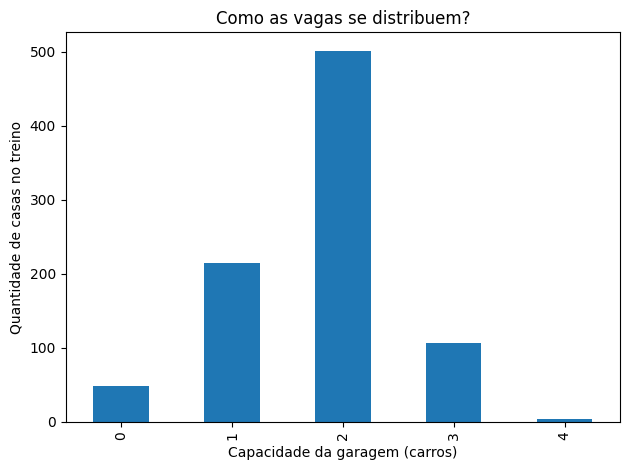

In [334]:
import matplotlib.pyplot as plt

# Desenhamos uma barra para cada capacidade de garagem.
garage_counts.plot.bar()

# Damos significado aos eixos e ao título.
plt.xlabel("Capacidade da garagem (carros)")
plt.ylabel("Quantidade de casas no treino")
plt.title("Como as vagas se distribuem?")

plt.tight_layout()

plt.show()

### O que essa distribuição de vagas sugere?

No treino, 501 das 876 casas têm capacidade para dois carros: cerca de **57%**, a categoria mais frequente. Há apenas quatro casas com quatro vagas. Essa diferença importa quando formos comparar preços: uma conclusão sobre quatro vagas terá muito menos exemplos por trás.

A contagem descreve quais casas aparecem nesta amostra. Ela ainda não demonstra que duas vagas aumentam o preço nem que categorias raras devem ser eliminadas. Para investigar preço, precisamos relacionar as colunas e olhar o tamanho dos grupos.

### Investigar a distribuição de quartos

Construam uma tabela com a quantidade e a porcentagem de casas para cada valor de `BedroomAbvGr`. Depois façam um gráfico em outra célula.

Comparem as categorias mais frequentes com as raras. Se há casas sem quarto acima do solo, isso basta para dizer que o cadastro está errado? Usem o significado da coluna para interpretar o resultado, não apenas a aparência do gráfico.

In [335]:
# Write your experiment here. Keep the original variables unchanged.
training_bedroom_capacity = train['BedroomAbvGr']
bedroom_counts = training_bedroom_capacity.value_counts(dropna=False)

bedroom_counts = bedroom_counts.sort_index()

bedroom_percentages = 100 * bedroom_counts / len(train)
bedroom_distribution = pd.DataFrame({
    "Count": bedroom_counts,
    "Percentage": bedroom_percentages
})
bedroom_distribution


,Count,Percentage
BedroomAbvGr,,
0,2,0.228311
1,22,2.511416
2,211,24.086758
3,488,55.707763
4,136,15.525114
5,10,1.141553
6,6,0.684932
8,1,0.114155


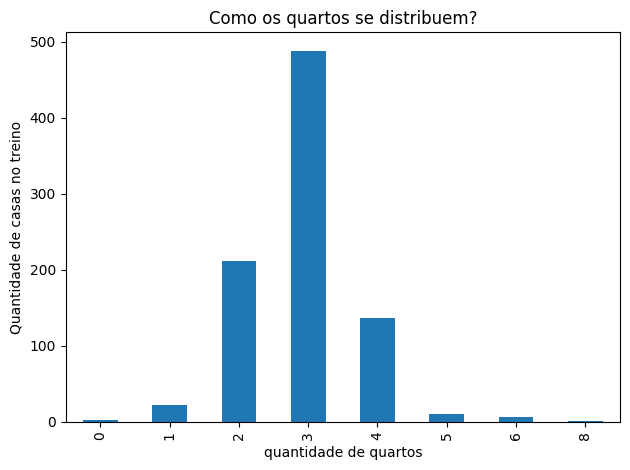

In [336]:
# Plot the distribution prepared in the previous cell.
import matplotlib.pyplot as plt
bedroom_counts.plot.bar()

plt.xlabel("quantidade de quartos")
plt.ylabel("Quantidade de casas no treino")
plt.title("Como os quartos se distribuem?")
plt.tight_layout()

plt.show()

## 11. Como os preços se distribuem?

Quando falamos em **distribuição dos preços**, queremos entender como as casas se espalham pelos valores: onde há muitas casas, onde há poucas e até onde chegam os preços. Não estamos dividindo treino e teste de novo. Aqui, distribuição é o padrão dos valores de uma coluna.

Na garagem, cada barra representava uma capacidade, como dois carros. Preço tem muitos valores possíveis, então vamos juntar valores próximos em **faixas**. Um histograma conta quantas casas caem em cada faixa. Por exemplo, uma barra para preços entre 100 mil e 150 mil dólares reúne todas as casas nesse intervalo.

A altura da barra indica frequência, ou seja, quantidade de casas. Uma barra alta não significa uma casa mais cara: o preço está no eixo horizontal. Faixas mais à direita correspondem a preços maiores.

Vamos olhar tanto o gráfico quanto medidas que resumem seus valores. Cada resumo responde a uma pergunta; nenhum deles descreve a tabela inteira sozinho.

[Referência sobre histogramas](https://www.itl.nist.gov/div898/handbook/eda/section3/histogra.htm).

### Primeiro, entender a média

Temos centenas de preços. Se alguém perguntar “em torno de quanto essas casas estão sendo vendidas?”, ler todos em voz alta não ajuda muito. Queremos um número que resuma o conjunto, mas precisamos saber **o que esse resumo representa**.

A **média aritmética** considera todos os preços e procura um ponto de equilíbrio entre eles. Imaginem cada casa como uma peça de mesmo peso numa régua, colocada na marca do seu preço. O apoio que equilibra essa régua fica na média: os afastamentos dos preços menores são compensados pelos afastamentos dos maiores. Vamos colocar números nessa ideia para ela não ficar só na imagem da balança.

Começamos com cinco casas fictícias. Nesta parte, os preços estão em **mil dólares**: 140 significa 140.000 dólares. A tabela está na ordem do cadastro, ainda sem ordenar os preços:

In [337]:
# Um único conjunto de cinco casas, antes de introduzir qualquer extremo.
price_center_example = pd.DataFrame({
    "PriceThousands": [140, 100, 150, 120, 130],
}, index=["A", "B", "C", "D", "E"])

price_center_example

,PriceThousands
A,140
B,100
C,150
D,120
E,130


### Encontrar esse equilíbrio no exemplo

A média desses preços será **128 mil dólares**. Vejam o que significa apoiar a régua no 128:

- Os preços 100 e 120 ficam abaixo dele, a distâncias de 28 e 8. Juntos, os afastamentos somam 36.
- Os preços 130, 140 e 150 ficam acima dele, a distâncias de 2, 12 e 22. Juntos, também somam 36.

É nesse sentido que 128 equilibra os cinco preços. A média usa o tamanho dos afastamentos, não só a quantidade de casas de cada lado. Aqui há duas abaixo e três acima da média.

Para encontrar esse número, fazemos a conta conhecida: somamos os preços e dividimos por cinco. `140 + 100 + 150 + 120 + 130 = 640`; `640 / 5 = 128`. No Pandas, `mean()` faz essa conta:

In [338]:
example_center_mean = price_center_example["PriceThousands"].mean()

example_center_mean

np.float64(128.0)

A média ficou em 128, embora nenhuma dessas casas custe exatamente 128 mil. Ela é um resumo que leva todos os preços em conta. Também não significa que a maioria custe 128 mil ou que o preço mais frequente seja esse.

### Agora, entender a mediana

A **mediana é o preço que fica no meio depois de colocar as casas em ordem de preço**. Ela responde à pergunta: “qual preço separa a parte mais barata da parte mais cara, contando as casas?”.

Na ordem original, o terceiro preço era 150. Pegar simplesmente a terceira linha do cadastro não resolve: primeiro precisamos ordenar do menor para o maior. Vamos fazer isso para enxergar o meio:

In [339]:
# Ordenamos para visualizar o meio, mantendo a identificação de cada casa.
ordered_center_example = price_center_example.sort_values("PriceThousands")

ordered_center_example

,PriceThousands
B,100
D,120
E,130
A,140
C,150


Lendo os preços de cima para baixo, temos **100, 120, 130, 140, 150**. O 130 está exatamente no meio: há duas casas mais baratas antes dele e duas mais caras depois dele. Portanto, a mediana é **130 mil dólares**. A identificação E à esquerda continua sendo o nome daquela casa; o que contamos aqui é sua posição na sequência ordenada.

Se houvesse quatro preços, como 100, 120, 140 e 150, não existiria uma única casa no meio. Usaríamos o meio entre os dois preços centrais, 120 e 140: `(120 + 140) / 2 = 130`. Nesse caso, a mediana também pode ser um valor que nenhuma casa tem.

O método `median()` já leva a ordenação dos valores em conta para calcular a mediana. Não precisamos ordenar a tabela antes de chamá-lo; fizemos isso acima só para vocês enxergarem quais valores ficam no meio:

In [340]:
example_center_median = price_center_example["PriceThousands"].median()

example_center_median

130.0

### E se uma das casas tivesse um preço muito maior?

Agora vamos trocar o preço da casa C, de 150 para **510 mil dólares**. Continuamos com cinco casas; não estamos acrescentando uma sexta. Assim conseguimos observar o efeito de mudar só o maior preço.

Antes de executar: esse 510 vai deslocar o equilíbrio da média? E vai mudar qual preço fica no meio depois da ordenação?

In [341]:
# Alteramos apenas uma cópia para preservar o primeiro exemplo.
outlier_center_example = price_center_example.copy()

outlier_center_example.loc["C", "PriceThousands"] = 510

outlier_center_example

,PriceThousands
A,140
B,100
C,510
D,120
E,130


O 510 ficou muito afastado dos outros quatro preços. Esse tipo de valor pode ser chamado de **valor atípico**, **valor extremo** ou **outlier**, sempre considerando o contexto. Aqui é um exemplo didático: não estamos dizendo que toda casa de 510 mil dólares esteja errada.

Vamos recalcular primeiro a média. A casa que estava em 150 foi para 510, aumentando o total dos preços em 360. Como ainda são cinco casas, a média sobe `360 / 5 = 72`: passa de 128 para **200 mil**.

In [342]:
outlier_center_mean = outlier_center_example["PriceThousands"].mean()

outlier_center_mean

np.float64(200.0)

A média 200 ficou acima dos preços de **quatro das cinco casas**. O valor alto deslocou o ponto de equilíbrio, mesmo sem mudar as outras quatro. Isso ajuda a entender por que a média pode dar uma impressão ruim do preço de uma casa comum quando há poucos imóveis muito caros.

Agora olhem a nova ordem: **100, 120, 130, 140, 510**. O preço do meio continua 130. Aumentar o último valor não mudou quais preços ocupam o centro:

In [343]:
outlier_center_median = outlier_center_example["PriceThousands"].median()

outlier_center_median

130.0

Depois de acompanhar cada conjunto, podemos reunir **só os resultados** para comparar:

In [344]:
center_example_summary = pd.DataFrame({
    "Example": ["Cinco preços iniciais", "Casa C passou de 150 para 510"],
    "Mean": [example_center_mean, outlier_center_mean],
    "Median": [example_center_median, outlier_center_median],
})

center_example_summary

,Example,Mean,Median
0,Cinco preços iniciais,128.0,130.0
1,Casa C passou de 150 para 510,200.0,130.0


### O que cada medida contou sobre essas casas?

A média considerou o tamanho de todos os preços e mudou de 128 para 200. A mediana acompanhou o meio da ordenação e permaneceu em 130. Não quer dizer que a mediana nunca mude: alterar os preços centrais ou acrescentar outras casas pode mudar esse meio. Ela costuma ser menos sensível a poucos valores muito distantes.

Podemos usar a mediana para descrever quanto custa uma casa na região central dos preços. Já a média ajuda quando o total envolvido também importa: no primeiro conjunto, `128 × 5 = 640` mil dólares; no segundo, `200 × 5 = 1.000` mil. Nenhuma delas conta sozinha o quanto os preços variam.

[Referência sobre medidas de centro](https://www.itl.nist.gov/div898/handbook/eda/section3/eda351.htm).

Vamos levar essas duas perguntas para os preços reais do treino. A partir da próxima célula, voltamos a **dólares**, sem a divisão por mil dos exemplos:

In [345]:
# As duas medidas usam somente os preços do treino.
price_mean = train["SalePrice"].mean()
price_median = train["SalePrice"].median()

In [346]:
training_center_summary = pd.DataFrame({
    "Mean": [price_mean],
    "Median": [price_median],
})

training_center_summary

,Mean,Median
0,181233.968037,164945.0


### Percentis: contar quantas casas custam menos que um preço

A mediana mostrou o meio das casas ordenadas pelo preço. Mas podemos querer saber outra coisa: **“quanto custam as casas da parte mais cara? A partir de que preço sobrariam só as 10% mais caras?”** Os percentis ajudam a responder.

Vamos usar outro exemplo fictício, agora com dez casas. Todos os preços abaixo estão em **mil dólares**, já do menor para o maior:

In [347]:
# A posição é só para acompanhar a contagem das dez casas ordenadas.
percentile_example = pd.DataFrame({
    "Position": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "PriceThousands": [100, 110, 120, 130, 140, 150, 160, 170, 180, 190],
})

percentile_example

,Position,PriceThousands
0,1,100
1,2,110
2,3,120
3,4,130
4,5,140
5,6,150
6,7,160
7,8,170
8,9,180
9,10,190


Se colocarmos um corte em **181 mil dólares**, quais casas custam esse valor ou menos? As de 100, 110, 120, 130, 140, 150, 160, 170 e 180: **nove das dez casas**, ou 90%. Só a de 190 fica acima desse preço.

O Pandas calcula **P90 = 181 mil** para esse exemplo. Portanto, dizer que “o P90 é 181” quer dizer que esse é o preço usado para separar aproximadamente as 90% casas mais baratas das 10% mais caras. O 90 conta casas; o 181 é um preço. Não estamos calculando 90% de 190 mil.

Por que 181, se não há uma casa com esse preço? Existem diferentes formas de calcular percentis. O padrão do Pandas encontra a posição correspondente a 90% na sequência e, quando ela fica entre duas casas, calcula um preço intermediário. Para dez preços, há nove intervalos entre o primeiro e o último. O padrão do Pandas percorre `90% × 9 = 8,1` intervalos a partir do primeiro: oito intervalos completos chegam ao preço 180, e falta um décimo do intervalo até 190. Assim, a conta fica: `180 + 0,1 × (190 - 180) = 181`. Essa conta entre valores é chamada de **interpolação**.

Vamos conferir o resultado do exemplo antes de voltar à base real:

In [348]:
example_p90 = percentile_example["PriceThousands"].quantile(0.90)

example_p90

np.float64(181.0)

### Quartis: olhar a parte mais barata, o meio e a parte mais cara

Se imaginarmos 100 casas ordenadas pelo preço, o **P25** fica na região em que terminam as primeiras 25 casas; o **P50**, na região em que terminam as primeiras 50; e o **P75**, na região em que terminam as primeiras 75. Eles também são chamados de **Q1, Q2 e Q3**, os quartis. Q2 é a mediana.

Esses cortes ajudam a responder perguntas como: “qual preço marca a região das 25% casas mais baratas?” ou “entre quais preços está a metade central das casas?”. Empates e a forma de interpolar podem fazer as contagens não corresponderem exatamente a 25%, 50% ou 75%, principalmente em conjuntos pequenos.

No código, `quantile(0.25)` pede P25 e `quantile(0.90)` pede P90. Podemos passar uma lista para pedir vários cortes. Agora vamos calcular os do treino, em **dólares**:

In [349]:
price_quantiles = train["SalePrice"].quantile([
    0.25,
    0.50,
    0.75,
    0.90,
])

price_quantiles

,SalePrice
0.25,130875.0
0.50,164945.0
0.75,213062.5
0.90,276250.0


### Traduzir esses números para as casas do treino

- **Q1 = 130.875 dólares:** aproximadamente um quarto das casas tem preço de até 130.875 dólares. Ele mostra onde termina a região dos menores preços, considerando a contagem das casas.
- **Mediana = 164.945 dólares:** é o meio da ordenação. Aproximadamente metade das casas custa esse valor ou menos e metade custa esse valor ou mais.
- **Q3 = 213.062,50 dólares:** aproximadamente três quartos das casas custam até esse valor. O quarto restante fica na região dos preços maiores.
- **P90 = 276.250 dólares:** cerca de 90% das casas custam até 276.250 dólares; as 10% restantes ficam acima, na parte mais cara.

Entre Q1 e Q3, de 130.875 dólares a 213.062,50 dólares, está aproximadamente **a metade central das casas**. Isso dá mais informação do que dizer apenas que a média é cerca de 181 mil dólares.

Os decimais de um corte não indicam necessariamente o preço de uma casa específica. Como vimos com 181 no exemplo, o resultado pode ficar entre dois valores observados.

Mais adiante, vamos fazer a mesma leitura nos erros das previsões. Um P90 de erro de 50 mil dólares significaria que cerca de 90% das previsões avaliadas ficaram a até 50 mil do preço real. As outras podem ter errado muito mais.

[Documentação de quantile e das opções de interpolação](https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html).

### Desvio padrão: casas perto ou longe da média?

Até aqui buscamos números que indiquem o centro dos preços ou separem grupos de casas pela ordenação. Agora a pergunta é outra: **os preços ficam apertados perto da média ou estão muito espalhados?**

Vamos olhar dois pequenos grupos, em **mil dólares**. No grupo A, os preços são 90, 100 e 110. No B, são 50, 100 e 150. Os dois têm média 100, mas no B as casas mais barata e mais cara estão muito mais longe desse valor:

In [350]:
spread_example = pd.DataFrame({
    "GroupA": [90, 100, 110],
    "GroupB": [50, 100, 150],
})

spread_example

,GroupA,GroupB
0,90,50
1,100,100
2,110,150


No grupo A, o menor e o maior preço estão a 10 mil da média 100. No B, estão a 50 mil. Portanto, dizer apenas “a média é 100” esconderia uma diferença importante entre esses grupos.

O **desvio padrão**, que aparece como `std` no Pandas, coloca essa ideia de espalhamento em um número. Ele considera os afastamentos de todos os preços em relação à média. Nestes exemplos, dará **10 mil para A** e **50 mil para B**: o segundo conjunto apresenta mais dispersão.

Usamos essa medida para perceber o quanto um resumo como a média pode esconder variações. Um desvio maior não significa automaticamente dados errados ou um modelo ruim. Aqui ainda estamos descrevendo preços, sem avaliar previsões. Vamos conferir os números e depois acompanhar a conta de um dos grupos:

In [351]:
spread_summary = pd.DataFrame({
    "Mean": spread_example.mean(),
    "Median": spread_example.median(),
    "Std": spread_example.std(),
})

spread_summary

,Mean,Median,Std
GroupA,100.0,100.0,10.0
GroupB,100.0,100.0,50.0


### Acompanhar a conta do grupo A

Os preços do grupo A são 90, 100 e 110, e sua média é 100. Subtraindo 100 de cada um, encontramos os **desvios**: -10, 0 e +10. A palavra desvio se refere justamente a esse afastamento de um valor em relação à média.

Somar os três daria zero, apesar de dois preços estarem afastados. O cálculo do desvio padrão começa elevando os desvios ao quadrado: `(-10)² = 100`, `0² = 0` e `10² = 100`. A soma é 200.

O Pandas divide essa soma por `n - 1` no cálculo padrão, sendo `n` a quantidade de preços conhecidos. Aqui temos três, então `200 / (3 - 1) = 100`. O resultado dessa etapa é a **variância**. Como usamos quadrados, ela está em “mil dólares ao quadrado”, uma unidade pouco direta para descrever um preço.

Por isso tiramos a raiz quadrada: `raiz de 100 = 10`. Voltamos à unidade dos preços, **mil dólares**, e chegamos ao desvio padrão 10. A conta do grupo B segue o mesmo caminho e dá 50.

O divisor `n - 1` é a convenção amostral. Usamos uma amostra, como estas casas, para estudar uma população maior, como outras vendas do mercado. Ele corrige a estimativa da variância pelo fato de a média também ter sido calculada com essa amostra. `ddof=1` é o padrão do Pandas que escolhe esse divisor; `ddof=0` usaria `n`.

Não precisamos decorar a fórmula agora. Para interpretar, guardem a pergunta: **quanto os preços se afastam da média por essa medida?** Extremos podem aumentar bastante esse número porque seus afastamentos entram ao quadrado. O desvio padrão não é uma distância que toda casa necessariamente apresenta, nem a maior distância do conjunto.

Vamos calcular agora o desvio dos preços reais do treino, em **dólares**:

In [352]:
training_price_std = train["SalePrice"].std()

training_price_std

77221.94203705215

### A média aumentou: os preços ficaram mais espalhados?

No exemplo anterior, trocar 150 por 510 fez a média subir de 128 para 200. Mas **uma média maior, sozinha, não prova maior dispersão**.

Para comparar, imaginem aumentar **todos** os cinco preços iniciais em 72 mil. Ordenados, eles virariam 172, 192, 202, 212 e 222. A média também seria 200, mas as distâncias entre as casas continuariam iguais. Nesse caso, o conjunto inteiro se deslocou, sem se espalhar mais.

Vamos comparar esses dois jeitos de chegar à média 200. A tabela abaixo usa os exemplos fictícios, em **mil dólares**:

In [353]:
# Um aumento igual para todas as casas preserva as distâncias entre os preços.
shifted_center_example = price_center_example.copy()

shifted_center_example["PriceThousands"] = (
    shifted_center_example["PriceThousands"] + 72
)

center_spread_comparison = pd.DataFrame({
    "Example": [
        "Preços iniciais",
        "Só o maior preço foi para 510",
        "Todos os preços aumentaram 72",
    ],
    "Mean": [
        price_center_example["PriceThousands"].mean(),
        outlier_center_example["PriceThousands"].mean(),
        shifted_center_example["PriceThousands"].mean(),
    ],
    "Std": [
        price_center_example["PriceThousands"].std(),
        outlier_center_example["PriceThousands"].std(),
        shifted_center_example["PriceThousands"].std(),
    ],
})

center_spread_comparison

,Example,Mean,Std
0,Preços iniciais,128.0,19.235384
1,Só o maior preço foi para 510,200.0,173.925271
2,Todos os preços aumentaram 72,200.0,19.235384


Quando só o extremo mudou, o desvio foi de aproximadamente **19,2 para 173,9 mil**: um único preço passou a ficar muito longe dos demais. Quando todos os preços subiram igualmente, a média aumentou, mas o desvio continuou **19,2 mil**. São situações diferentes que a média 200, sozinha, não distinguiria.

Também não podemos concluir que todo o grupo se espalhou porque o desvio subiu. Na mudança do extremo, quatro preços ficaram exatamente onde estavam. Para saber se a região central também mudou, olhamos os quartis e o gráfico.

### Interpretar o desvio dos preços reais

No treino das casas, a média é cerca de **181 mil dólares** e o desvio padrão é cerca de **77,2 mil dólares**. Nessa escala, a variação merece atenção: não estamos diante de casas com preços quase iguais, apertados em torno da média. Mas não existe um número universal a partir do qual o desvio vira “alto” para qualquer base.

Lembrem também dos quartis: a metade central vai de aproximadamente **130,9 mil a 213,1 mil dólares**, uma faixa de **82,2 mil dólares**. Já o menor preço é 34,9 mil e o maior, 745 mil. Isso sugere uma região central bem mais concentrada que o alcance total, com alguns preços altos estendendo a distribuição. O desvio considera esses afastamentos grandes, por isso o lemos junto dos quartis e do histograma.

Uma diferença de 77 mil dólares tem significado diferente numa base de imóveis de 180 mil e numa base de imóveis de 10 milhões. A unidade também importa: converter os mesmos preços para centavos multiplicaria o desvio por 100 sem mudar nenhuma casa. Por isso não classificamos o resultado apenas pelo tamanho do número.

Esse desvio descreve os **preços**, não o erro de uma previsão. Ele também não garante que cada casa esteja a essa distância da média.

[Documentação de std e do divisor usado no cálculo](https://pandas.pydata.org/docs/reference/api/pandas.Series.std.html).

### Ler describe sem tratar a saída como uma lista de números soltos

`describe()` reúne os resumos que acabamos de estudar:

| Campo | O que ele indica aqui |
|---|---|
| `count` | Quantidade de preços não ausentes que entraram nas contas |
| `mean` | Média dos preços |
| `std` | Desvio padrão amostral dos preços |
| `min` | Menor preço observado |
| `25%` | Q1, o percentil 25 |
| `50%` | Mediana, o percentil 50 |
| `75%` | Q3, o percentil 75 |
| `max` | Maior preço observado |

Mínimo e máximo mostram o alcance observado, mas dependem de dois registros. Os quartis ajudam a enxergar a região central. O gráfico mostra formas e agrupamentos que esses números podem esconder.

In [354]:
train['SalePrice'].describe()

,SalePrice
count,876.000000
mean,181233.968037
std,77221.942037
min,34900.000000
25%,130875.000000
50%,164945.000000
75%,213062.500000
max,745000.000000


### Voltar dos resumos para o histograma

Vamos observar os preços reais do treino. `bins=20` pede vinte faixas; cada barra conta as casas de uma faixa. Mudar a quantidade de faixas muda o detalhe da apresentação, sem mudar os preços. Faixas muito largas podem esconder agrupamentos; faixas muito estreitas podem destacar ruído da amostra.

As linhas verticais marcam a média e a mediana que já calculamos. Reparem onde fica a maior concentração e para que lado se estendem os casos menos frequentes.

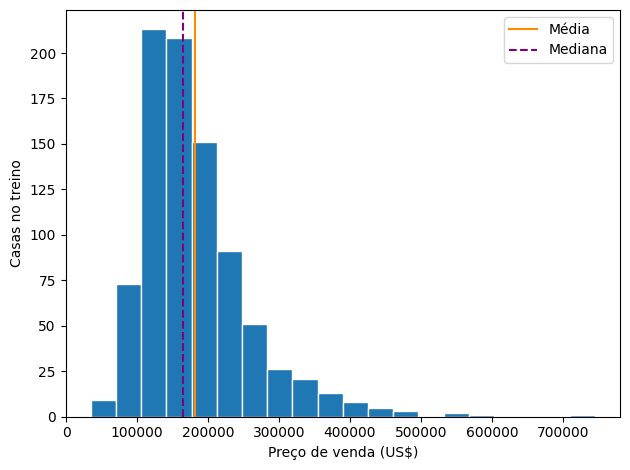

In [355]:
# O histograma agrupa os preços em faixas.
plt.hist(train["SalePrice"], bins=20, edgecolor="white")

# As linhas destacam a média e a mediana calculadas antes.
plt.axvline(price_mean, color="darkorange", label="Média")
plt.axvline(price_median, color="purple", linestyle="--", label="Mediana")

plt.xlabel("Preço de venda (US$)")
plt.ylabel("Casas no treino")
plt.legend()

plt.tight_layout()

plt.show()

### Como ler o formato que apareceu?

No treino, os preços se concentram nas faixas mais baixas e intermediárias, com poucas casas muito caras estendendo a **cauda para a direita**. Chamamos isso de **assimetria à direita**. O nome se refere à direção da cauda, mesmo que as barras mais altas estejam à esquerda.

A média ficou acima da mediana, o que é compatível com a influência desses preços altos. Essa comparação é uma pista; sozinha, não identifica toda a forma da distribuição.

Uma distribuição com cauda longa para valores baixos seria assimétrica à esquerda. Um formato aproximadamente espelhado em torno do centro seria simétrico. Também podemos ter dois ou mais agrupamentos de valores, sem uma única região central bem definida.

Essas diferenças importam: uma média isolada pode esconder casas de mercados muito distintos, e uma cauda longa pode levar poucos registros a influenciar bastante os cálculos. Precisamos do gráfico e de outros resumos para interpretar isso.

### E o que seria uma distribuição normal?

A **distribuição normal** é um modelo matemático com formato de sino, simétrico em torno da média. Nesse modelo, média e mediana coincidem; valores próximos do centro são mais comuns e valores muito distantes ficam progressivamente menos frequentes. A média localiza o centro e o desvio padrão controla a largura.

Para visualizar a diferença, vamos gerar dados **fictícios** a partir de uma normal com média 100 e desvio 15. Usaremos NumPy, uma biblioteca para cálculos numéricos, apenas para criar essa amostra. Não estamos transformando os preços das casas nem afirmando que eles sejam normais. Em uma amostra finita, as barras não precisam formar um sino perfeitamente simétrico.

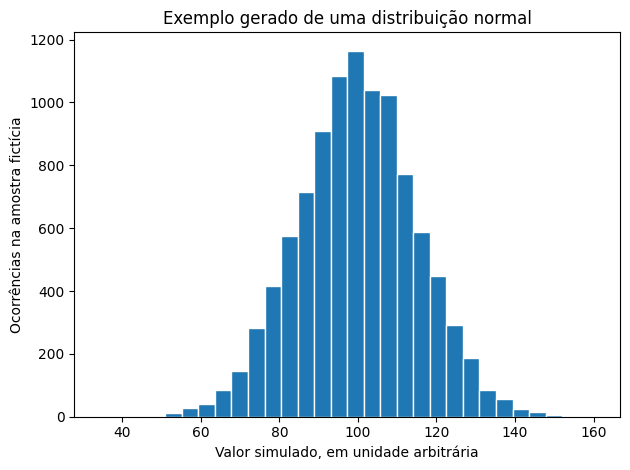

In [356]:
import numpy as np

# Criamos uma amostra fictícia, sem alterar os dados ou o sorteio das casas.
normal_rng = np.random.default_rng(42)
normal_example = normal_rng.normal(loc=100, scale=15, size=10000)

plt.hist(normal_example, bins=30, edgecolor="white")

plt.xlabel("Valor simulado, em unidade arbitrária")
plt.ylabel("Ocorrências na amostra fictícia")
plt.title("Exemplo gerado de uma distribuição normal")

plt.tight_layout()
plt.show()

No exemplo normal fictício, o centro está em 100 e o desvio é 15. A região de maior concentração fica perto de 100; valores próximos de 40 ou 160 são bem menos frequentes. Comparem isso com a cauda longa dos preços das casas: os dois histogramas contam histórias diferentes.

Para uma distribuição normal, cerca de 68% dos valores ficam entre **85 e 115**, isto é, 15 abaixo ou acima de 100. Cerca de 95% ficam entre **70 e 130**, dois desvios de cada lado. Esses percentuais descrevem o modelo normal; na amostra fictícia podem variar um pouco.

Não vamos transportar essas faixas para as casas sem verificar as hipóteses. Uma média e um desvio, sozinhos, não demonstram normalidade. Também não precisamos que preços ou entradas sejam normais para calcular os resumos ou treinar os modelos deste estudo. Uma assimetria pode ser uma característica real do mercado que precisamos compreender.

[Referência sobre a normal](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3661.htm). [Referência sobre assimetria](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35b.htm).

### Comparar preços e áreas

Calculem os mesmos resumos para `GrLivArea` e montem um histograma em outra célula, com a unidade correta. Depois comparem os dois histogramas: onde está a concentração e como aparecem os valores mais distantes?

Experimentem também outra quantidade de faixas e confiram o que mudou na apresentação. Os registros são os mesmos. O que essa escolha facilita enxergar e o que pode esconder?

In [357]:
# Write your experiment here. Keep the original variables unchanged.
train['GrLivArea'].describe()

,GrLivArea
count,876.000000
mean,1532.142694
std,530.679852
min,334.000000
25%,1154.000000
50%,1480.000000
75%,1790.500000
max,5642.000000


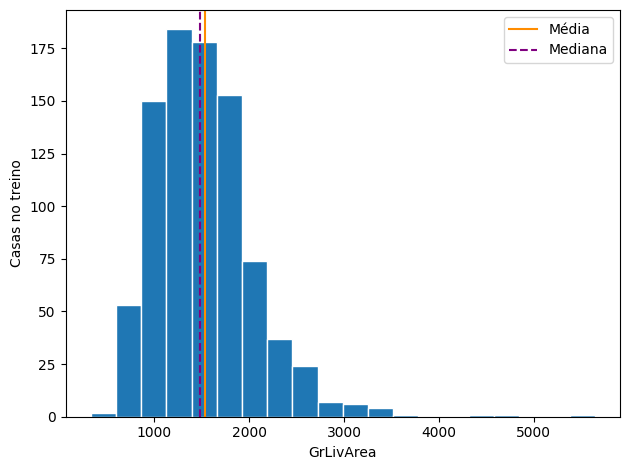

In [358]:
# Build the area histogram and compare another bin count in a new cell.
# O histograma agrupa os preços em faixas.
plt.hist(train["GrLivArea"],  bins=20, edgecolor="white")

area_mean = train["GrLivArea"].mean()
area_median = train["GrLivArea"].median()

# As linhas destacam a média e a mediana calculadas antes.
plt.axvline(area_mean, color="darkorange", label="Média")
plt.axvline(area_median, color="purple", linestyle="--", label="Mediana")

plt.xlabel("GrLivArea")
plt.ylabel("Casas no treino")
plt.legend()

plt.tight_layout()

plt.show()

## 12. Investigar valores extremos

Um **outlier**, ou valor atípico, é uma observação que se destaca das demais no contexto que estamos olhando. Uma casa muito mais cara que a maioria pode ser um caso para investigar. Isso não significa, por si só, que o registro esteja errado.

Pode ser uma casa de luxo verdadeira, um zero digitado a mais, uma área em outra unidade ou um caso que só parece estranho porque estamos ignorando o bairro e outras características. Um preço incomum na base inteira pode ser comum em um grupo específico.

### Usar os quartis para criar uma marcação de investigação

Já conhecemos Q1 e Q3. A distância entre eles é o **intervalo interquartil**, ou **IQR**: `IQR = Q3 - Q1`. Ele resume a largura da região central dos dados, aproximadamente os 50% do meio. Uma vantagem é não depender diretamente do menor e do maior preço.

Vamos marcar preços abaixo de `Q1 - 1,5 × IQR` ou acima de `Q3 + 1,5 × IQR`. O fator 1,5 é uma convenção exploratória usada em boxplots, não uma lei do mercado nem uma fronteira entre certo e errado. Em uma distribuição assimétrica, vários casos legítimos podem ultrapassar esse limite.

Por exemplo, se Q1 fosse 100 mil e Q3 fosse 200 mil dólares, o IQR seria 100 mil. Os limites seriam -50 mil e 350 mil. O limite negativo é resultado da conta; não torna um preço negativo válido. Isso mostra por que precisamos interpretar a marcação junto do significado dos dados.

O código repete os quartis do treino para mostrar o cálculo completo. `|` combina as condições com o sentido de “ou”; a máscara terá `True` onde o preço ultrapassar algum limite. Nenhuma casa será removida.

[Referência sobre identificação e investigação de outliers](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm).

In [359]:
# Primeiro localizamos os dois quartis nos preços do treino.
price_q1 = train["SalePrice"].quantile(0.25)
price_q3 = train["SalePrice"].quantile(0.75)

# Depois calculamos a distância entre eles.
price_iqr = price_q3 - price_q1

# Usamos essa distância para definir os limites de investigação.
price_low = price_q1 - 1.5 * price_iqr
price_high = price_q3 + 1.5 * price_iqr

# Marcamos preços abaixo do limite inferior OU acima do superior.
price_flags = (
    (train["SalePrice"] < price_low)
    | (train["SalePrice"] > price_high)
)

# Como antes, somar os booleanos conta as linhas marcadas com True.
outlier_summary = pd.DataFrame({
    "LowerLimit": [price_low],
    "UpperLimit": [price_high],
    "FlaggedHouses": [price_flags.sum()],
})

In [360]:
outlier_summary

,LowerLimit,UpperLimit,FlaggedHouses
0,7593.75,336343.75,37


### O que a marcação de extremos mostrou?

Com essa escolha de 1,5 IQR, **37 das 876 casas**, cerca de **4,2%**, foram marcadas. Neste treino, todas ultrapassam o limite superior, de aproximadamente **336,3 mil dólares**; nenhuma ficou abaixo do limite inferior, de cerca de 7,6 mil.

Isso combina com a cauda de preços altos que vimos no histograma. A conta encontrou uma parte pequena da amostra para investigar, não “37 erros comprovados”. Se excluíssemos essas casas automaticamente, passaríamos a estudar um mercado com menos imóveis caros.

Vamos olhar os registros para levantar hipóteses: são casas maiores? Estão em bairros específicos? O preço faz sentido quando consideramos essas características? A marcação é o começo dessa investigação.

In [361]:
outlier_columns = [
    "Id",
    "SalePrice",
    "GrLivArea",
    "Neighborhood",
]

flagged_houses = train.loc[price_flags, outlier_columns]

flagged_houses.head()

,Id,SalePrice,GrLivArea,Neighborhood
688,689,392000,1419,StoneBr
803,804,582933,2822,NridgHt
1388,1389,377500,1746,Gilbert
378,379,394432,1856,StoneBr
644,645,370878,1766,Somerst


### Ler o boxplot com os preços que já conhecemos

O boxplot é uma forma de desenhar os cortes que acabamos de estudar. Leiam o gráfico de baixo para cima, porque o preço está no eixo vertical:

- A base da caixa está em **Q1**, aqui cerca de 130,9 mil dólares.
- A linha dentro da caixa marca a **mediana**, cerca de 164,9 mil dólares.
- O topo da caixa está em **Q3**, cerca de 213,1 mil dólares.

Assim, a caixa mostra a faixa em que está aproximadamente a metade central das casas. Ela não mostra os preços de todas as casas separadamente. Sua altura é a distância `Q3 - Q1`, que chamamos de IQR.

As linhas que saem da caixa são os **bigodes**. Nesta configuração, seguimos para baixo e para cima até o preço observado mais distante que ainda não ultrapassou os limites de 1,5 IQR. Os pontos além desses bigodes são os preços que marcamos para investigar.

Um ponto fora da caixa não é necessariamente um outlier: vários preços ficam fora dela e ainda dentro dos bigodes. E um ponto além dos bigodes também não prova erro de cadastro. É um alerta para olhar a casa com mais informações.

[Referência sobre boxplots](https://www.itl.nist.gov/div898/handbook/eda/section3/boxplot.htm). [Configuração dos bigodes no Matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html).

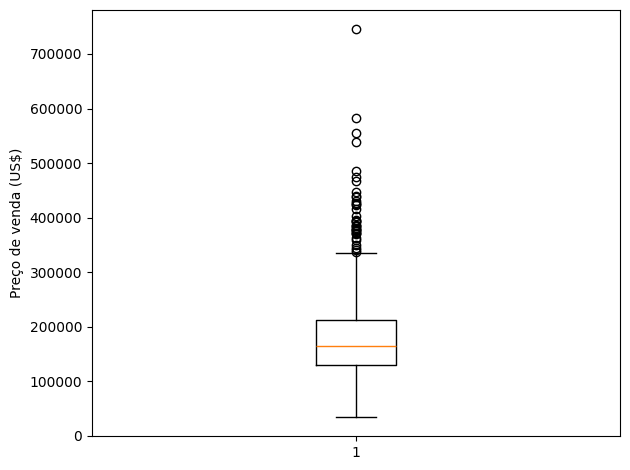

In [362]:
plt.boxplot(train["SalePrice"])

plt.ylabel("Preço de venda (US$)")

plt.tight_layout()

plt.show()

### Por que um outlier pode importar para o modelo?

O efeito depende da informação e do algoritmo. Um preço alto verdadeiro não é automaticamente um problema; o risco é ignorar o quanto certos registros influenciam o ajuste e o resultado da avaliação.

- **Nos resumos:** extremos podem deslocar a média e aumentar muito o desvio padrão. A mediana e o IQR costumam ser menos sensíveis a poucos valores muito distantes.
- **Na regressão com erro quadrático:** um erro cinco vezes maior contribui com 25 vezes mais erro ao quadrado. Poucos casos podem pesar bastante no ajuste. Uma entrada muito distante, como uma área enorme, também pode influenciar a regressão; estar longe não garante, sozinho, que isso ocorrerá.
- **Em métodos que usam distâncias:** uma medida extrema pode alterar a comparação de proximidade entre exemplos. Valores extremos nas entradas também podem afetar classificação. Ser classificação ou regressão não basta para determinar a sensibilidade.
- **Na avaliação:** alguns erros enormes podem aumentar o erro médio. Por isso vamos olhar a média e também os casos individuais e percentis dos erros.

Primeiro conferimos unidade, significado e possível erro de cadastro. Se o caso for verdadeiro, podemos mantê-lo, investigar grupos, transformar a representação ou comparar métodos mais robustos. Excluir todas as casas caras mudaria o problema: deixaríamos de avaliar justamente parte do mercado. Neste percurso, mantemos todos os registros; há uma alternativa de tratamento para testar depois.

### Investigar áreas extremas

Calculem Q1, Q3 e IQR para `GrLivArea`, usando nomes como `area_q1` e `area_flags`. Montem uma tabela com identificação, área, preço e bairro dos registros marcados, ordenada pela área.

Depois façam um gráfico de área e preço destacando esses registros. A casa é extrema só em área ou também destoa da relação entre área e preço? Levantem uma hipótese a partir do que apareceu. Não removam casas automaticamente.

In [363]:
# Write your experiment here. Keep the original variables unchanged.
# Primeiro localizamos os dois quartis nos preços do treino.
area_q1 = train["GrLivArea"].quantile(0.25)
area_q3 = train["GrLivArea"].quantile(0.75)

# Depois calculamos a distância entre eles.
area_iqr = area_q3 - area_q1

# Usamos essa distância para definir os limites de investigação.
area_low = area_q1 - 1.5 * area_iqr
area_high = area_q3 + 1.5 * area_iqr

# Marcamos preços abaixo do limite inferior OU acima do superior.
area_flags = (
    (train["GrLivArea"] < area_low)
    | (train["GrLivArea"] > area_high)
)


# Criar tabela com identificação, área, preço e bairro
area_outliers = train.loc[
    area_flags,
    ["Id", "GrLivArea", "SalePrice", "Neighborhood"]
].copy()

# Ordenar pela área
area_outliers = area_outliers.sort_values(
    by="GrLivArea",
    ascending=True
)

# Mostrar a tabela
area_outliers

,Id,GrLivArea,SalePrice,Neighborhood
1386,1387,2784,250000,NWAmes
1312,1313,2810,302000,NoRidge
803,804,2822,582933,NridgHt
1142,1143,2828,424870,CollgCr
961,962,2872,272000,NWAmes
1031,1032,3082,197000,SWISU
197,198,3112,235000,NAmes
798,799,3140,485000,NridgHt
608,609,3194,359100,Crawfor
118,119,3222,320000,SawyerW


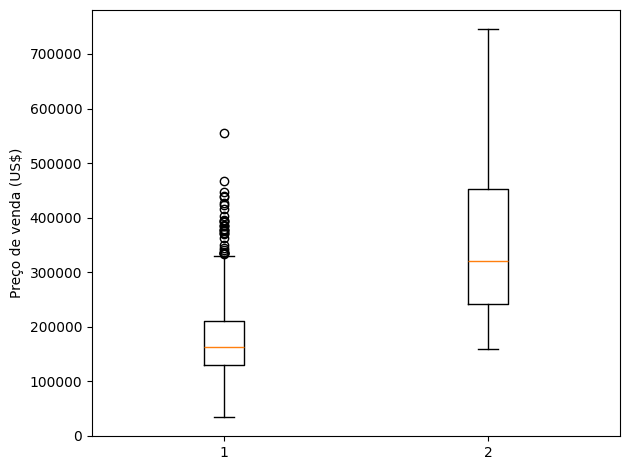

In [364]:
# Compare flagged and unflagged records in the area-price plot.
plt.boxplot([
    train.loc[~area_flags, "SalePrice"], #casas que não estão em áreas extremas
    train.loc[area_flags, "SalePrice"] #extremas
])
plt.ylabel("Preço de venda (US$)")

plt.tight_layout()

plt.show()

## 13. Relacionar características ao preço

Até aqui olhamos uma coluna por vez. No **gráfico de dispersão**, cada ponto representa uma casa: sua posição horizontal mostra a área e a vertical mostra o preço. Se os pontos tendem a subir quando andamos para a direita, há uma associação positiva entre área e preço.

Isso pode indicar uma característica útil para prever. Não quer dizer que toda casa maior seja mais cara nem que a área explique tudo. Casas com a mesma área podem ter preços diferentes por bairro, acabamento e outras informações. Uma associação observada também não prova que alterar uma característica causaria aquela diferença de preço.

Depois vamos comparar os preços em grupos de capacidade da garagem. `count` indica quantas casas com preço conhecido sustentam cada grupo e `median` resume o preço central. A mediana de um grupo de duas casas tem muito menos informação por trás do que a de um grupo de duzentas. Para comparar, precisamos olhar as duas medidas.

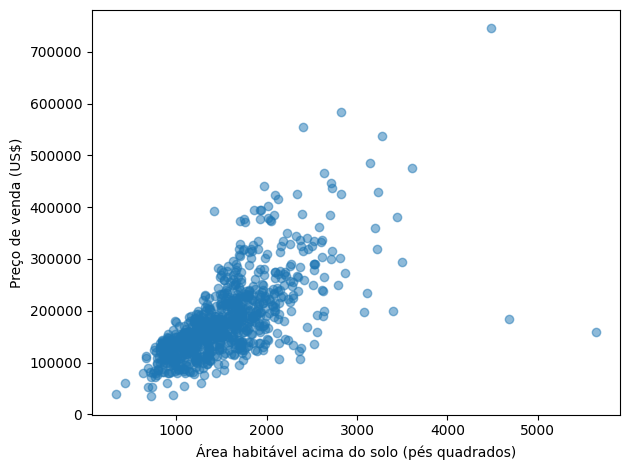

In [365]:
plt.scatter(train["GrLivArea"], train["SalePrice"], alpha=0.5)

plt.xlabel("Área habitável acima do solo (pés quadrados)")
plt.ylabel("Preço de venda (US$)")

plt.tight_layout()

plt.show()

In [366]:
# Agrupamos as casas que têm a mesma capacidade de garagem.
garage_groups = train.groupby("GarageCars")

# agg calcula duas medidas dos preços de cada grupo.
garage_prices = garage_groups["SalePrice"].agg(["count", "median"])

In [367]:
garage_prices

,count,median
GarageCars,,
0,49,97000.0
1,215,128000.0
2,501,178000.0
3,107,290000.0
4,4,203150.0


### Ler a comparação entre preço e vagas

No treino, a mediana do preço aumenta de **97 mil dólares**, nas casas sem vagas, para **128 mil**, com uma vaga, **178 mil**, com duas, e **290 mil**, com três. Isso sugere uma associação que pode ser útil para prever, mas ainda não separa o efeito da garagem do tamanho, bairro ou acabamento.

O grupo com quatro vagas tem mediana de aproximadamente **203,2 mil dólares**, menor que o de três vagas. Antes de concluir que a quarta vaga reduz preço, olhem a quantidade: são só **quatro casas**, contra 107 com três vagas. A composição de um grupo tão pequeno pode mudar bastante o resumo.

Portanto, a tabela não demonstra quanto construir uma vaga valorizaria um imóvel. Ela ajuda a escolher o que investigar: comparar áreas, bairros e características das casas, além de observar se a relação reaparece em outros dados.

### Comparar bairros sem perder o tamanho dos grupos

Agrupem por `Neighborhood` e calculem quantidade de casas e mediana de `SalePrice`. Ordenem o resultado pela mediana. Depois façam outro recorte com bairros que tenham pelo menos 20 casas no treino.

O topo da comparação mudou? Qual seria o problema de apresentar só a mediana, sem a quantidade de registros? Usem as duas tabelas, em células separadas, para sustentar a interpretação.

In [368]:
# Write your experiment here. Keep the original variables unchanged.
# Agrupamos as casas que têm a mesma Neighborhood.
neighborhood_groups = train.groupby("Neighborhood")

# agg calcula duas medidas dos preços de cada grupo.
neighborhood_prices = neighborhood_groups["SalePrice"].agg(["count", "median"]).sort_values('median', ascending=True)
neighborhood_prices

,count,median
Neighborhood,,
MeadowV,5,88000.0
BrDale,10,103000.0
IDOTRR,21,109900.0
BrkSide,35,120000.0
OldTown,70,123000.0
Edwards,65,126000.0
Sawyer,46,133950.0
SWISU,16,139750.0
NAmes,130,142362.5


In [421]:
# Compare groups with at least 20 training records.
neighborhood_prices = neighborhood_prices[neighborhood_prices["count"] >= 20]

neighborhood_prices = neighborhood_prices[
    neighborhood_prices["count"] >= 20
]

neighborhood_prices


,count,median
Neighborhood,,
IDOTRR,21,109900.0
BrkSide,35,120000.0
OldTown,70,123000.0
Edwards,65,126000.0
Sawyer,46,133950.0
NAmes,130,142362.5
Mitchel,34,161000.0
SawyerW,36,179200.0
NWAmes,53,181000.0


# Preparar e treinar
## 14. Definir o primeiro experimento

Vamos montar uma primeira referência usando as oito características do recorte: área, quartos, banheiros completos e parciais, vagas, bairro e anos de construção e venda. São escolhas iniciais para testar, não uma afirmação de que essas são as únicas informações relevantes. O conjunto continua com casas de todas as capacidades de garagem.

Aqui a preparação mínima é conferir os campos e colocar as entradas no formato que o algoritmo recebe. Neste recorte não encontramos ausências; não vamos preencher valores sem necessidade. Para a regressão linear, vamos representar o bairro com números. Não precisamos excluir casas por preço alto, filtrar por vagas ou aplicar um scaler para conseguir esse primeiro resultado.

`SalePrice` será a resposta `y`, então fica fora de `X`. `Id` também fica fora das entradas: é identificação. Usamos cópias para preparar as tabelas de trabalho sem alterar os registros de origem.

Depois de medir essa referência, vocês podem formular uma hipótese e mudar uma decisão: incluir uma coluna de `all_houses`, criar uma informação, trocar a representação de categorias ou testar outra preparação. A comparação será na mesma validação, mantendo o teste para o fim. A ideia é ver se a mudança ajuda, em vez de tratar cada escolha inicial como uma receita obrigatória.

In [370]:
numeric_columns = [
    "GrLivArea",
    "BedroomAbvGr",
    "FullBath",
    "HalfBath",
    "GarageCars",
    "YearBuilt",
    "YrSold",
]

feature_columns = numeric_columns + ["Neighborhood"]

# X contém as informações que o modelo receberá como entrada.
X_train_raw = train[feature_columns].copy()
X_validation_raw = validation[feature_columns].copy()

# y contém o preço conhecido, que será a resposta a prever.
y_train = train["SalePrice"]
y_validation = validation["SalePrice"]

In [371]:
X_train_raw.head(3)

,GrLivArea,BedroomAbvGr,FullBath,HalfBath,GarageCars,YearBuilt,YrSold,Neighborhood
683,1668,3,2,0,3,2002,2007,CollgCr
1077,1096,3,1,0,1,1969,2006,NAmes
463,1660,3,1,1,1,1934,2008,Crawfor


In [372]:
y_train.head(3)

,SalePrice
683,285000
1077,138800
463,188700


## 15. Representar bairro com one-hot encoding

Queremos que o modelo use a informação do bairro. Mas essa informação chega como um nome, e a regressão recebe entradas numéricas. Precisamos representá-la em números sem inventar relações entre os nomes.

Se Centro fosse 1, Praia fosse 2 e outro bairro fosse 3, a regressão poderia tratar a passagem de 1 para 2 como a mesma diferença numérica da passagem de 2 para 3. Essa sequência foi uma escolha nossa; ela não mede distância, localização nem valorização dos bairros.

Com **one-hot encoding**, cada bairro ganha uma coluna de indicador. Na coluna Centro, uma casa do Centro recebe 1 e uma casa da Praia recebe 0. Na coluna Praia, ocorre o contrário. O 1 significa “pertence a este bairro”, não “este bairro é melhor”.

Vamos ver isso primeiro em uma tabela fictícia com Centro e Praia. `get_dummies` cria os indicadores e `dtype=int` deixa os valores como números inteiros. Depois de executar, confiram as duas linhas que eram Centro: elas precisam receber a mesma representação.

In [373]:
category_example = pd.DataFrame({"Neighborhood": ["Centro", "Praia", "Centro"]})

In [374]:
category_example

,Neighborhood
0,Centro
1,Praia
2,Centro


In [375]:
pd.get_dummies(category_example, columns=['Neighborhood'], dtype=int)

,Neighborhood_Centro,Neighborhood_Praia
0,1,0
1,0,1
2,1,0


Agora aplicamos a mesma técnica às casas. O treino determina quais colunas o modelo conhece. Como alguma categoria pode não aparecer em uma das partes, `reindex(columns=X_train.columns, fill_value=0)` alinha a validação às colunas do treino, na mesma ordem.

Uma categoria inédita ficará com zero em todos os indicadores de bairro. Isso permite executar a previsão, mas não ensina como é morar naquele bairro. `get_dummies` e `OneHotEncoder` são duas ferramentas para a mesma técnica; o laboratório de codificação apresenta também outras representações.

O `get_dummies` é chamado nas duas tabelas, mas o conjunto final de colunas vem do treino. Não vamos juntar treino e validação para descobrir uma nova representação. No caminho com `OneHotEncoder`, essa reutilização aparece diretamente como `fit` no treino e `transform` nas demais partes.

In [376]:
# Criamos os indicadores de bairro nas duas tabelas.
X_train = pd.get_dummies(
    X_train_raw,
    columns=["Neighborhood"],
    dtype=int,
)

X_validation = pd.get_dummies(
    X_validation_raw,
    columns=["Neighborhood"],
    dtype=int,
)

# A validação precisa ter as mesmas colunas do treino, na mesma ordem.
X_validation = X_validation.reindex(
    columns=X_train.columns,
    fill_value=0,
)

encoding_sizes = pd.DataFrame({
    "Representation": ["Antes do one-hot", "Depois do one-hot"],
    "Rows": [len(X_train_raw), len(X_train)],
    "Columns": [X_train_raw.shape[1], X_train.shape[1]],
})

In [377]:
encoding_sizes

,Representation,Rows,Columns
0,Antes do one-hot,876,8
1,Depois do one-hot,876,31


Indicadores de bairro:

In [378]:
X_train.columns[7:].tolist()

['Neighborhood_Blmngtn',
 'Neighborhood_BrDale',
 'Neighborhood_BrkSide',
 'Neighborhood_ClearCr',
 'Neighborhood_CollgCr',
 'Neighborhood_Crawfor',
 'Neighborhood_Edwards',
 'Neighborhood_Gilbert',
 'Neighborhood_IDOTRR',
 'Neighborhood_MeadowV',
 'Neighborhood_Mitchel',
 'Neighborhood_NAmes',
 'Neighborhood_NPkVill',
 'Neighborhood_NWAmes',
 'Neighborhood_NoRidge',
 'Neighborhood_NridgHt',
 'Neighborhood_OldTown',
 'Neighborhood_SWISU',
 'Neighborhood_Sawyer',
 'Neighborhood_SawyerW',
 'Neighborhood_Somerst',
 'Neighborhood_StoneBr',
 'Neighborhood_Timber',
 'Neighborhood_Veenker']

### Mais colunas não significam mais casas

Nas entradas do treino, passamos de **oito colunas para 31**, porque os 24 bairros conhecidos viraram indicadores, junto das sete características numéricas. Continuam sendo as mesmas 876 casas. A informação de bairro mudou de formato; não ganhamos novas vendas para aprender.

Isso permite à regressão associar cada bairro ao preço sem impor aquela sequência artificial de códigos. Ainda precisamos medir se o modelo usa essas informações de uma forma útil. Uma tabela maior, sozinha, não é evidência de melhora.

## 16. Ter uma referência e entender o erro

Conhecer os preços da base e avaliar previsões são duas perguntas diferentes. Média, mediana e desvio padrão descrevem os dados. Agora queremos medir **quanto uma previsão se afastou do preço que já conhecemos**.

Antes de treinar uma regressão, vamos acompanhar essa conta em três casas fictícias. O preço observado é a resposta conhecida; a previsão é o valor que um modelo teria estimado. Todos os valores abaixo estão em dólares.

In [379]:
error_example = pd.DataFrame({
    "ObservedPrice": [100000, 150000, 200000],
    "Prediction": [80000, 170000, 200000],
})

error_example

,ObservedPrice,Prediction
0,100000,80000
1,150000,170000
2,200000,200000


### Resíduo: a previsão ficou acima ou abaixo?

Vamos usar **resíduo = preço observado menos previsão**. O sinal preserva a direção do erro:

- Na primeira casa, `100.000 - 80.000 = +20.000`: o modelo previu abaixo do preço observado, uma subestimação.
- Na segunda, `150.000 - 170.000 = -20.000`: previu acima, uma superestimação.
- Na terceira, `200.000 - 200.000 = 0`: a previsão coincidiu com o preço observado.

Para medir o tamanho do erro de cada casa, usamos o **erro absoluto**. Ele retira o sinal: +20 mil e -20 mil têm a mesma distância de 20 mil. Assim, a direção e a distância ficam disponíveis em colunas diferentes:

In [380]:
# O resíduo mantém o sinal para indicar a direção do erro.
error_example["Residual"] = (
    error_example["ObservedPrice"] - error_example["Prediction"]
)

# O erro absoluto mede a distância, sem cancelar sinais diferentes.
error_example["AbsoluteError"] = error_example["Residual"].abs()

error_example

,ObservedPrice,Prediction,Residual,AbsoluteError
0,100000,80000,20000,20000
1,150000,170000,-20000,20000
2,200000,200000,0,0


### Por que não usar só a média dos resíduos?

Aqui os resíduos somam zero: `20.000 - 20.000 + 0 = 0`. A média também é zero, mas houve dois erros de 20 mil. Erros em sentidos opostos se cancelaram.

O **MAE**, do inglês *Mean Absolute Error*, é a **média dos erros absolutos**. Primeiro medimos a distância de cada previsão, depois somamos e dividimos pela quantidade de casas. Neste exemplo: `(20.000 + 20.000 + 0) / 3 = 13.333,33` dólares.

In [381]:
example_absolute_error_sum = error_example["AbsoluteError"].sum()

example_mae = example_absolute_error_sum / len(error_example)
example_mean_residual = error_example["Residual"].mean()

example_error_summary = pd.DataFrame({
    "MeanResidual": [example_mean_residual],
    "MAE": [example_mae],
})

example_error_summary

,MeanResidual,MAE
0,0.0,13333.333333


### O que esse MAE permite concluir?

As previsões ficaram, em média, a 13.333,33 dólares dos preços conhecidos nesse pequeno conjunto. Isso **não** significa 13,33% de erro, nem que cada casa errou esse valor, nem que nenhum erro ultrapassou esse número. Duas casas, por exemplo, ficaram a 20 mil.

Um MAE de zero indica coincidência em todas as previsões avaliadas. Para os mesmos casos e na mesma unidade, menor MAE significa menor distância absoluta média. Para dizer se o resultado é útil, precisamos do contexto: preço das casas, custo de errar e uma referência de comparação. Também pode haver grupos nos quais o resultado seja bem pior que a média geral.

[Referência sobre MAE](https://scikit-learn.org/stable/modules/model_evaluation.html#mean-absolute-error).

### Criar uma referência antes do modelo

E se prevíssemos **a mediana dos preços do treino para toda casa**, sem olhar área, bairro ou outra entrada? Isso é uma referência simples, chamada também de baseline. Ela nos ajuda a verificar se usar essas características acrescenta algo.

A mediana é uma escolha coerente com MAE: entre previsões constantes, uma mediana minimiza a soma dos erros absolutos **nos dados usados para calculá-la**. Isso não garante o menor erro na validação; lá precisamos medir. A média seria a escolha correspondente ao erro quadrático, que vamos comentar na regressão.

`DummyRegressor(strategy="median")` implementa essa referência. `fit` calcula a mediana no treino, `predict` repete esse valor para as casas da validação e `mean_absolute_error` faz a conta que acabamos de decompor. O desvio padrão dos preços e o MAE respondem a perguntas diferentes: variação dos preços e erro das previsões, respectivamente.

In [382]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

# Criamos a referência que sempre prevê a mediana dos preços do treino.
reference = DummyRegressor(strategy="median")

# fit calcula e guarda essa mediana usando os dados de treino.
reference.fit(X_train, y_train)

# predict produz as previsões para as casas de validação.
reference_predictions = reference.predict(X_validation)

# Comparamos as previsões com os preços conhecidos dessas casas.
reference_mae = mean_absolute_error(y_validation, reference_predictions)

reference_mae

56131.69520547945

## 17. Treinar uma regressão linear

O modelo aprende uma combinação das entradas para prever o preço. `fit(X_train, y_train)` ajusta essa combinação usando as casas de treino com preço conhecido. `predict(X_validation)` recebe apenas as entradas das casas de validação; os preços conhecidos ficam guardados para a comparação posterior.

### Erro de ajuste e erro de avaliação

A regressão linear comum ajusta seus parâmetros minimizando a **soma dos erros ao quadrado** no treino. Com uma quantidade fixa de casas, minimizar essa soma ou sua média leva à mesma escolha de parâmetros. A média desses quadrados é chamada **MSE**. O quadrado evita cancelamento de sinais e dá mais peso a erros grandes: 50 mil dólares de erro geram 25 vezes o quadrado de um erro de 10 mil.

O MSE fica em dólares ao quadrado, então é menos direto de interpretar como uma distância em dinheiro. A raiz quadrada dele, **RMSE**, volta à unidade de dólares e continua dando peso maior a erros grandes do que o MAE. São alternativas de avaliação, com prioridades diferentes.

Aqui mantemos **MAE para comunicar e comparar os resultados**. Não precisamos usar como medida de avaliação exatamente a mesma expressão que o algoritmo minimiza no treino.

Também vamos calcular MAE no treino. Se ele for baixo no treino e bem maior na validação, isso pode indicar dificuldade de generalizar para outras casas. Os dois números próximos, por si só, também não provam que o modelo é bom: ele ainda precisa melhorar a referência e atender ao objetivo da previsão.

[Referência sobre métricas de regressão](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics).

In [383]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

# Ajustamos o modelo usando somente o treino.
linear_model.fit(X_train, y_train)

# Fazemos previsões nas duas partes para comparar os erros.
linear_predictions = linear_model.predict(X_validation)
linear_train_predictions = linear_model.predict(X_train)

linear_mae = mean_absolute_error(y_validation, linear_predictions)
linear_train_mae = mean_absolute_error(y_train, linear_train_predictions)

linear_metrics = pd.DataFrame({
    "TrainingMAE": [linear_train_mae],
    "ValidationMAE": [linear_mae],
    "ChangeFromReference": [linear_mae - reference_mae],
})

linear_metrics

,TrainingMAE,ValidationMAE,ChangeFromReference
0,24432.233911,24319.238503,-31812.456703


### O primeiro resultado ajuda em relação à referência?

Na validação, o MAE caiu de aproximadamente **56,1 mil dólares**, na referência que sempre prevê a mediana, para **24,3 mil dólares**, na regressão. A redução é de cerca de **31,8 mil dólares de distância absoluta média por casa**, neste conjunto. Usar as características ajudou segundo essa comparação.

Isso ainda pode ser insuficiente para uma aplicação real. Errar 24 mil numa casa de 100 mil tem um impacto diferente de errar 24 mil numa de 700 mil. O MAE também pode esconder bairros ou tipos de imóveis em que o modelo erra mais. Vamos investigar esses casos antes de concluir que o resultado atende ao objetivo.

O MAE de treino ficou perto de **24,4 mil dólares**, próximo do de validação. Não apareceu uma grande diferença entre os dois nesta divisão. Isso não prova que o modelo captou tudo: um modelo limitado também pode errar de forma parecida nos dois conjuntos.

## 18. Onde o modelo errou?

O MAE resume várias casas em um único número. Agora queremos descobrir quais erros ele está resumindo e se há um padrão que sugira algo a investigar.

Vamos reunir entradas, preço real, previsão, resíduo e erro absoluto das mesmas casas de validação. Mantemos a convenção do exemplo: **resíduo = observado menos previsto**. `abs()` retira o sinal; a ordenação por erro absoluto mostra as maiores distâncias primeiro.

In [384]:
analysis_columns = [
    "Id",
    "GrLivArea",
    "BedroomAbvGr",
    "Neighborhood",
    "SalePrice",
]

validation_analysis = validation[analysis_columns].copy()

# Acrescentamos as previsões às mesmas casas que usamos na validação.
validation_analysis["Prediction"] = linear_predictions

validation_analysis["Residual"] = (
    validation_analysis["SalePrice"] - validation_analysis["Prediction"]
)

# abs transforma o resíduo em distância, sem sinal negativo.
validation_analysis["AbsoluteError"] = validation_analysis["Residual"].abs()

In [385]:
validation_analysis.sort_values('AbsoluteError', ascending=False).head(5)

,Id,GrLivArea,BedroomAbvGr,Neighborhood,SalePrice,Prediction,Residual,AbsoluteError
1169,1170,3627,4,NoRidge,625000,403109.112280,221890.887720,221890.887720
1181,1182,1652,2,Crawfor,392500,245337.474156,147162.525844,147162.525844
178,179,2234,1,StoneBr,501837,356469.477216,145367.522784,145367.522784
53,54,1842,0,Veenker,385000,262834.663365,122165.336635,122165.336635
1324,1325,1795,2,Somerst,147000,267495.276205,-120495.276205,120495.276205


### Reutilizar mediana e P90 para entender os erros

Antes ordenamos **preços**. Agora podemos ordenar **o tamanho dos erros**, do menor para o maior. A lógica é a mesma, mas a coluna mudou.

A mediana do erro absoluto indica a distância que fica no meio dessa ordenação: aproximadamente metade das previsões errou menos que esse valor e metade errou mais. O P90 do erro absoluto ajuda a separar os 90% menores erros dos 10% maiores. Por exemplo, P90 de 50 mil dólares significa que aproximadamente nove de cada dez casas avaliadas tiveram erro de até 50 mil. As demais podem ter erros muito maiores.

O máximo é o maior erro que apareceu nesta validação, não um limite para qualquer casa futura. Já a média dos resíduos mantém os sinais: positiva indica subestimação média e negativa indica superestimação média, pela convenção observado menos previsto. Vimos no exemplo que uma média perto de zero pode esconder erros que se cancelam.

Vamos reunir essas leituras em uma tabela, sempre em dólares:

In [386]:
validation_error_summary = pd.DataFrame({
    "Measure": [
        "Resíduo médio",
        "MAE",
        "Mediana do erro absoluto",
        "P90 do erro absoluto",
        "Maior erro absoluto",
    ],
    "US_Dollars": [
        validation_analysis["Residual"].mean(),
        validation_analysis["AbsoluteError"].mean(),
        validation_analysis["AbsoluteError"].median(),
        validation_analysis["AbsoluteError"].quantile(0.90),
        validation_analysis["AbsoluteError"].max(),
    ],
})

validation_error_summary

,Measure,US_Dollars
0,Resíduo médio,1003.666429
1,MAE,24319.238503
2,Mediana do erro absoluto,16199.000936
3,P90 do erro absoluto,50777.510159
4,Maior erro absoluto,221890.887720


### Ler observado versus previsto

No gráfico seguinte, o eixo horizontal mostra o preço previsto e o vertical, o observado. A diagonal marca previsões iguais ao valor observado. Um ponto acima dela indica que a casa custou mais do que previmos; abaixo, que previmos um preço maior que o observado. Quanto mais distante da diagonal, maior o erro naquela escala.

### Como interpretar esses tamanhos de erro?

Nesta validação, a mediana do erro absoluto é cerca de **16,2 mil dólares**, enquanto o MAE é **24,3 mil**. O valor médio maior é compatível com alguns erros grandes puxando o resumo para cima; a mediana ajuda a enxergar a posição central dessas distâncias.

O **P90 fica em cerca de 50,8 mil dólares**. Portanto, aproximadamente nove em cada dez casas avaliadas tiveram erros de até esse tamanho. A região restante contém os casos mais difíceis, e o maior erro chegou a aproximadamente **221,9 mil dólares**. Um MAE de 24,3 mil não nos permitiria perceber sozinho esse caso tão distante.

Já o resíduo médio foi positivo em cerca de **1 mil dólar**. Ele sugere uma subestimação média pequena, mas isso não quer dizer previsões quase exatas: erros grandes em sentidos opostos se compensam nesse resumo. Para entender a qualidade, precisamos ler direção, distância e casos extremos em conjunto.

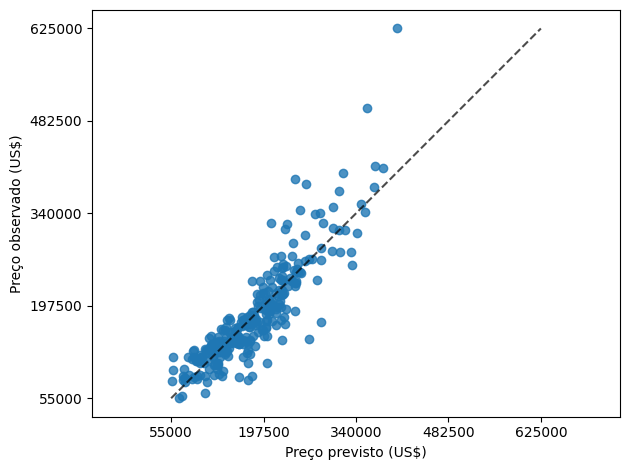

In [387]:
from sklearn.metrics import PredictionErrorDisplay

PredictionErrorDisplay.from_predictions(
    y_validation,
    linear_predictions,
    kind="actual_vs_predicted",
    random_state=42,
)

plt.xlabel("Preço previsto (US$)")
plt.ylabel("Preço observado (US$)")

plt.tight_layout()

plt.show()

### Ler resíduos versus previsões

Aqui o eixo vertical passa a mostrar o resíduo. A linha horizontal em zero representa acerto. Acima dela estão subestimações; abaixo, superestimações. Uma distância de 50 mil até essa linha corresponde a 50 mil dólares de erro absoluto.

Procuramos concentração e padrões: resíduos predominantemente de um lado em certa faixa de preço, uma curva ou dispersão que cresce com o preço. Esses sinais podem sugerir relações que o modelo não captou ou grupos com comportamentos diferentes. Não provam, sozinhos, a causa do problema. Uma nuvem sem padrão evidente também não garante ausência de problemas.

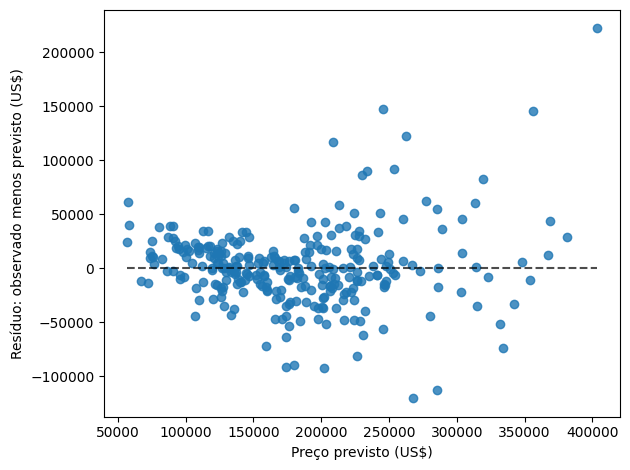

In [388]:
PredictionErrorDisplay.from_predictions(
    y_validation,
    linear_predictions,
    kind="residual_vs_predicted",
    random_state=42,
)

plt.xlabel("Preço previsto (US$)")
plt.ylabel("Resíduo: observado menos previsto (US$)")

plt.tight_layout()

plt.show()

### A distribuição dos resíduos é outra distribuição

Agora vamos contar em faixas os resíduos da validação. O eixo horizontal é **erro com sinal**, não preço. Uma concentração perto de zero indica muitas previsões próximas do observado; caudas longas revelam erros grandes em uma ou nas duas direções.

Esse histograma não precisa ter o mesmo formato do histograma dos preços. E uma média de resíduos próxima de zero não obriga essa distribuição a ser normal nem faz o MAE ser pequeno.

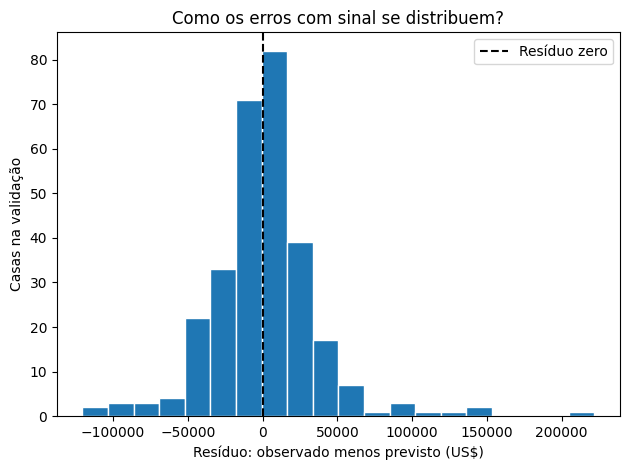

In [389]:
plt.hist(validation_analysis["Residual"], bins=20, edgecolor="white")

plt.axvline(0, color="black", linestyle="--", label="Resíduo zero")

plt.xlabel("Resíduo: observado menos previsto (US$)")
plt.ylabel("Casas na validação")
plt.title("Como os erros com sinal se distribuem?")
plt.legend()

plt.tight_layout()
plt.show()

Olhando esses casos, qual erro vocês investigariam primeiro? Escolham uma casa e relacionem a previsão às informações disponíveis. O que o modelo não conseguiu representar? Que dado adicional ajudaria a conferir essa hipótese?

Se forem testar uma mudança, deixem a hipótese perto do código para depois comparar com o resultado.

## 19. Uma mudança resolvida: usar a idade na venda

Vamos trocar a representação dos dois anos pela diferença `YrSold - YearBuilt`. Essa idade se refere à venda, sem depender do ano atual. A pergunta é se a representação ajuda a regressão linear nesta validação.

Mantemos as mesmas casas e o mesmo algoritmo. Mudamos apenas a forma de representar o tempo. Nomes novos preservam as entradas originais. Uma representação plausível pode melhorar ou piorar o resultado.

In [390]:
# Criamos cópias sem as duas colunas que serão substituídas.
X_train_age = X_train.drop(columns=["YearBuilt", "YrSold"]).copy()
X_validation_age = X_validation.drop(columns=["YearBuilt", "YrSold"]).copy()

X_train_age["HouseAge"] = train["YrSold"] - train["YearBuilt"]
X_validation_age["HouseAge"] = validation["YrSold"] - validation["YearBuilt"]

age_model = LinearRegression()

age_model.fit(X_train_age, y_train)

age_predictions = age_model.predict(X_validation_age)

age_mae = mean_absolute_error(y_validation, age_predictions)

age_comparison = pd.DataFrame({
    "Representation": ["Anos separados", "Idade na venda"],
    "ValidationMAE": [linear_mae, age_mae],
})

age_comparison

,Representation,ValidationMAE
0,Anos separados,24319.238503
1,Idade na venda,24387.376317


### A representação por idade melhorou?

O MAE com a idade ficou em aproximadamente **24.387 dólares**, contra **24.319 dólares** com os anos separados. Nesta divisão e com essa regressão, a mudança não reduziu o erro; a diferença foi de cerca de 68 dólares na média.

A leitura não é que “idade não importa”. Ao substituir dois anos por uma diferença, mudamos o que o modelo consegue representar. A escolha faz sentido como hipótese, mas não trouxe vantagem nesta comparação. Uma diferença pequena numa única validação também não demonstra uma regra geral sobre qual representação sempre será melhor.

## 20. Outro algoritmo com as mesmas entradas

Vamos comparar uma árvore com profundidade máxima 5. Ela aprende divisões das entradas, em vez de uma combinação linear. O limite controla a complexidade; 5 é uma configuração inicial para estudar, não um valor ótimo comprovado.

Aqui voltamos às entradas originais, sem a troca por idade. Assim, a comparação com a primeira regressão muda o algoritmo, mantendo a representação.

In [391]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_validation)

tree_mae = mean_absolute_error(y_validation, tree_predictions)

comparison = pd.DataFrame({
    "Model": [
        "Median reference",
        "Linear regression",
        "Linear + age",
        "Decision tree",
    ],
    "ValidationMAE": [
        reference_mae,
        linear_mae,
        age_mae,
        tree_mae,
    ],
})

In [392]:
comparison.sort_values('ValidationMAE')

,Model,ValidationMAE
1,Linear regression,24319.238503
2,Linear + age,24387.376317
3,Decision tree,29889.798806
0,Median reference,56131.695205


### O que aprendemos comparando os algoritmos?

A árvore com profundidade 5 teve MAE de aproximadamente **29,9 mil dólares**, maior que os **24,3 mil** da primeira regressão. Ela usa um método diferente, mas isso não a tornou melhor com estas entradas e esta configuração. A primeira regressão continua sendo a melhor opção pelo MAE das quatro tentativas resolvidas.

Esse resultado não mostra, sozinho, por que a árvore perdeu. Para investigar excesso de ajuste, por exemplo, precisaríamos comparar seus erros no treino e na validação ao variar a profundidade. Não basta olhar o erro de validação e chamar o problema de memorização. O laboratório deixa esse caminho aberto.

# Alternativas para testar

Até aqui temos modelos treinados, previsões e uma comparação. Agora dá para escolher uma decisão e testar outro caminho. Os exemplos anteriores de filtro eram consultas; aqui as mudanças passam a ser hipóteses sobre a preparação ou o modelo, com comparação de erro na validação. Esses experimentos são opcionais e não são necessários para executar a conclusão do percurso resolvido.

Usem nomes próprios para cada tentativa e mantenham as mesmas partições. A validação serve para comparar os resultados das tentativas. No primeiro exemplo abaixo, vamos ver o cuidado necessário ao calcular um valor para preencher uma ausência. Antes de rodar, deixem uma hipótese curta junto do código. Depois confiram se o resultado sustentou essa expectativa.

As opções abaixo não entram automaticamente na seleção final de `comparison`. Para escolher uma delas, terminem a comparação na validação e adaptem a preparação do teste antes de executar o bloco final. Os tutoriais ficam para consulta; usem a parte que ajudar no experimento.

### Incluir uma coluna da base completa

O recorte inicial deixou várias características de fora. Consultem o dicionário e escolham uma para testar. Um ponto de partida é `OverallQual`, uma avaliação ordenada do material e acabamento do imóvel. Que diferença vocês esperam que essa informação faça na previsão?

Façam cópias de `X_train` e `X_validation` em `extra_train` e `extra_validation`. Acrescentem a coluna escolhida a partir de `all_houses`, usando `train.index` e `validation.index` para buscar as mesmas casas, na ordem correta. Confiram tipo, significado e valores ausentes antes de treinar. Se o campo precisar de preparação, aprendam as regras apenas no treino.

Treinem outra regressão linear e comparem o MAE com `linear_mae`. Mantenham as demais entradas e configurações para investigar o efeito dessa informação. Não alterem o modelo inicial nem consultem o teste nessa tentativa.

Para localizar os valores do treino, por exemplo, vocês podem usar `all_houses.loc[train.index, "OverallQual"]`. O campo escolhido também precisa ser uma informação disponível no momento em que a previsão seria feita.

[Dicionário da base completa](https://raw.githubusercontent.com/Rswcf/houseprices_kaggle/017cd478d912a0af0b754808191dbff45478bc47/data_description.txt).

In [393]:
# Add one source feature to separate training and validation copies; compare validation MAE.

## 21. Como preencher um valor ausente?

Nas colunas usadas para treinar, não encontramos ausências. Mas e se uma casa estivesse sem a área informada? A regressão deste percurso precisa de um número nessa entrada. Substituir a ausência por uma estimativa é uma das operações que chamamos de **preparação dos dados**.

Poderíamos usar média ou mediana das áreas conhecidas. Já vimos por que essas medidas podem dar respostas diferentes quando existe um valor distante. Aqui escolhemos a mediana para demonstrar o procedimento; isso não a torna a melhor escolha em qualquer problema.

Antes de preencher, também precisamos entender por que a informação falta. “Não foi medido” e “não existe garagem”, por exemplo, têm significados diferentes. Colocar um número no lugar vazio não resolve automaticamente essa interpretação.

Vamos usar tabelas **fictícias e isoladas das casas do modelo**, representando treino, validação e teste. `None` marca a área não informada e será mostrado como `NaN` pelo Pandas.

In [394]:
missing_example = pd.DataFrame({"Area": [80, 90, None, 100, 300]})

O treino fictício, antes de preencher:

In [395]:
missing_example

,Area
0,80.0
1,90.0
2,NaN
3,100.0
4,300.0


Vamos retomar a verificação que fizemos antes. Agora a máscara vai ter um `True` exatamente na posição que está sem a área:

In [396]:
example_missing_mask = missing_example.isna()

example_missing_mask

,Area
0,False
1,False
2,True
3,False
4,False


Somando essa máscara por coluna, encontramos uma ausência em `Area`:

In [397]:
example_missing_counts = example_missing_mask.sum()

example_missing_counts

,0
Area,1


### Qual número vamos colocar no espaço vazio?

Vamos calcular a mediana **somente das áreas conhecidas do treino**. `median()` desconsidera o valor ausente. Os valores ordenados são 80, 90, 100 e 300; como há quatro valores, a mediana é o meio entre 90 e 100: **95**.

In [398]:
# O valor de preenchimento é calculado apenas no treino fictício.
example_median = missing_example["Area"].median()

example_median

95.0

Agora usamos esse 95 para preencher o treino. `fillna` troca apenas os valores ausentes; as áreas já informadas continuam iguais. Guardamos a nova tabela em outra variável para comparar com a original:

In [399]:
# fillna substitui somente as ausências e devolve outra tabela.
filled_train_example = missing_example.fillna({"Area": example_median})

filled_train_example

,Area
0,80.0
1,90.0
2,95.0
3,100.0
4,300.0


### E quando a ausência está na validação?

Aqui está nossa validação fictícia. Ela também tem uma área não informada:

In [400]:
validation_missing_example = pd.DataFrame({"Area": [200, None, 240]})

validation_missing_example

,Area
0,200.0
1,NaN
2,240.0


Vamos usar **o mesmo 95 calculado no treino**. Reparem que não aparece outro `.median()` no código abaixo. A validação recebe o preenchimento que já definimos para o modelo:

In [401]:
# Reutilizamos a mediana do treino, sem calcular outra na validação.
filled_validation_example = validation_missing_example.fillna({"Area": example_median})

filled_validation_example

,Area
0,200.0
1,95.0
2,240.0


### O preenchimento é uma estimativa, não uma descoberta

Na validação fictícia, as áreas informadas eram 200 e 240. A ausência recebeu **95**, porque esse foi o número calculado no treino. O código conseguiu produzir uma tabela completa, mas não descobriu que a área verdadeira era 95.

O exemplo deixa visível uma limitação: uma mesma estimativa pode representar mal certas casas ou grupos. Em um problema real, podemos comparar outras formas de preencher e investigar por que faltam valores. Essa comparação usa a validação; os valores de preenchimento continuam sendo calculados no treino.

### Por que não calcular a mediana na base inteira?

Se juntássemos essas tabelas antes de calcular a mediana, as áreas da validação e do teste também mudariam o número usado para preencher o treino. O modelo receberia dados preparados com ajuda de casas que deveriam estar fora do seu ajuste. Isso é uma forma de **vazamento de dados**.

E calcular uma mediana diferente na validação? Também não é o caminho que estamos avaliando. A ideia é usar um procedimento definido com os dados de treino, inclusive quando chegarem novas casas. Neste exemplo, esse procedimento é bem concreto: preencher áreas ausentes com 95. Ao comparar os modelos, queremos avaliar esse procedimento junto com eles.

Por isso, separamos duas operações: **calcular o valor no treino** e **usar esse valor para preencher onde for necessário**. Se escolhêssemos a média em vez da mediana, o cuidado seria o mesmo.

### O teste também precisa ser preenchido?

Sim, se houver valores ausentes na coluna que decidimos preencher. Na avaliação final, o teste deve receber o mesmo tratamento que o modelo recebeu no treino. Usamos o 95 já calculado, sem obter uma nova mediana a partir do teste.

Vamos mostrar isso com o teste fictício. O teste das casas continua reservado para o fim do estudo:

In [402]:
test_missing_example = pd.DataFrame({"Area": [260, None, 300]})

test_missing_example

,Area
0,260.0
1,NaN
2,300.0


O preenchimento usa novamente `example_median`: nenhuma conta nova para escolher o valor.

In [403]:
# O teste recebe o mesmo valor que já foi definido no treino.
filled_test_example = test_missing_example.fillna({"Area": example_median})

filled_test_example

,Area
0,260.0
1,95.0
2,300.0


E aí, conseguem acompanhar de onde veio cada 95? Calculamos uma vez no treino e usamos nas três tabelas. Uma casa nova, depois dessa avaliação, também receberia esse preenchimento caso viesse sem a área informada.

No scikit-learn, `SimpleImputer` pode fazer essas etapas. `fit` no treino calcula e guarda a mediana; `transform` preenche os espaços usando esse valor guardado. Por isso fazemos `fit` só no treino e `transform` no treino, na validação e, ao final, no teste. No exemplo com Pandas, fizemos essas mesmas etapas explicitamente com `median()` e `fillna()`.

Isso também ajuda a distinguir as contas anteriores. Converter área para metros quadrados usa o fator 0,09290304, que já conhecemos sem consultar as outras casas. A mediana 95, por outro lado, foi calculada a partir de um conjunto de áreas. É nesse cálculo que precisamos manter validação e teste de fora.

[Exemplos de vazamento de dados e como evitá-lo](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage). [Documentação de fillna, com exemplos](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.fillna.html).

### Testar outra forma de preencher

Calculem a média de `missing_example`, o treino fictício, e usem esse valor para preencher cópias das três tabelas. Comparem os preenchimentos pela média e pela mediana. Que diferença o valor 300 no treino faz nessa comparação?

Depois reproduzam uma das opções com `SimpleImputer`. Façam `fit` em `missing_example` e `transform` em cada tabela, incluindo a de treino. Confiram se os valores coincidem com o preenchimento manual. Usem outras variáveis para preservar os exemplos resolvidos.

Aqui comparamos os valores preenchidos nas tabelas fictícias. Não estamos treinando outro modelo das casas nem calculando um novo MAE. Em outros problemas, também podemos considerar moda, constante ou métodos baseados em outras variáveis; a escolha depende do significado do campo e da ausência.

[Tutorial com estratégias de preenchimento](https://scikit-learn.org/stable/auto_examples/impute/plot_missing_values.html). [SimpleImputer, com exemplos de fit e transform](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html).

In [404]:
# Write your experiment here. Keep the original variables unchanged.

## 22. Categorias: ferramentas e representações alternativas

No percurso resolvido, Centro e Praia viraram colunas de 0 e 1 com `get_dummies`. **OneHotEncoder** faz essa mesma técnica e guarda, no `fit`, os bairros conhecidos no treino. Depois usa essa lista para transformar outras casas. Trocar a ferramenta sem mudar a representação deve produzir entradas equivalentes quando as opções são equivalentes.

**OrdinalEncoder** usa um código por categoria, como Centro=0 e Praia=1. A tabela fica com menos colunas, mas o tamanho do código pode ganhar um sentido que o bairro não tinha. Para uma classificação de acabamento “ruim, médio, bom” existe uma ordem conhecida; para nomes de bairros, essa ordem não está dada.

Na **codificação por frequência**, um bairro que apareça em metade das casas do treino pode receber 0,5. Isso informa o quanto ele é frequente, mas bairros diferentes com a mesma frequência podem acabar com o mesmo número.

Na **codificação pelo alvo**, poderíamos usar uma estatística dos preços de cada bairro. Ela utiliza a resposta que queremos prever e exige cuidado adicional: se o preço da própria casa ajudar a construir sua entrada de treino, podemos facilitar artificialmente o ajuste. O tutorial mostra como separar esses cálculos. Nenhuma dessas alternativas é automaticamente melhor; vamos comparar as previsões na mesma validação.

### Se quiserem testar: outra codificação de bairro

Escolham um caminho:

1. **Mesma técnica, outra ferramenta:** usem `OneHotEncoder(handle_unknown="ignore", sparse_output=False)`, façam `fit` em `train[["Neighborhood"]]` e `transform` na validação. Observem os nomes e a quantidade de colunas. Ao criar DataFrames, preservem `index=train.index` e `index=validation.index`; `pd.concat(..., axis=1)` alinha as linhas pelo índice.
2. **Outra representação:** usem `OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)`. Juntem bairro codificado às mesmas sete entradas numéricas, treinem outra regressão e comparem o MAE. Discutam a ordem artificial imposta aos bairros, mesmo se o erro melhorar.

[Tutorial comparando one-hot, ordinal e codificação pelo alvo](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_target_encoder.html). [Exemplos de OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html). [Exemplos de OrdinalEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html).

Usem `encoded_train`, `encoded_validation` e `encoded_model`; preservem `X_train` e `X_validation`.

In [405]:
# Write your experiment here. Keep the original variables unchanged.

## 23. Escala: mudar a representação dos números

Já vimos o que o desvio padrão informa sobre a dispersão. Agora ele também pode ajudar a expressar uma entrada em outra escala. Uma área em pés quadrados e um ano de construção têm ordens de grandeza diferentes; alguns algoritmos são sensíveis a isso.

**StandardScaler** subtrai a média do treino e divide pelo desvio padrão do treino. Um valor 120, com média 100 e desvio 10, vira `(120 - 100) / 10 = 2`: ele está dois desvios acima da média. Um valor na média vira zero e valores abaixo dela ficam negativos. Isso não significa que uma área negativa passou a existir: é outra representação da mesma área.

**MinMaxScaler** usa os limites do treino para reescalar, normalmente entre 0 e 1 no próprio treino. Uma casa nova fora dos limites conhecidos pode resultar fora desse intervalo. **RobustScaler** usa mediana e IQR e tende a ser menos sensível a extremos na definição da escala. Ele não apaga nem corrige esses extremos.

Esses métodos são alternativas. Aprendemos seus valores no treino e reaplicamos na validação e, ao final, no teste. Padronizar não transforma uma distribuição assimétrica em normal. Uma cauda longa continua existindo depois de mudar a unidade.

No `StandardScaler`, o cálculo usa a convenção de desvio com divisor `n`, equivalente a `ddof=0`, enquanto o `.std()` que vimos no Pandas usa `n - 1` por padrão. A ideia de escala é a mesma, mas os números podem diferir um pouco.

Na regressão linear comum sem penalização, uma mudança invertível apenas na escala das entradas tende a preservar as previsões, salvo efeitos numéricos. Métodos baseados em distâncias ou regressões com penalização podem reagir de outra forma.

[Documentação de StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).

Depois da transformação, um valor 2 no exemplo de StandardScaler descreve o afastamento em relação à média do treino; não é um preço nem uma nota de qualidade da casa. Não basta ver média perto de zero e desvio perto de um para concluir que o modelo melhorou. O critério da comparação continua sendo seu erro na validação, em dólares.

### Se quiserem testar: outra escala para os números

Copiem `X_train` e `X_validation` para `scaled_train` e `scaled_validation`. Aprendam um scaler apenas nas sete colunas numéricas do treino. Usem a mesma transformação na validação, mantendo os indicadores de bairro. Treinem uma regressão e comparem seu MAE com `linear_mae`. Os preços continuam em dólares.

[Tutorial visual e executável comparando scalers](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_all_scaling.html).

Se o erro quase não mudar, expliquem por que isso pode estar correto.

In [406]:
# Write your experiment here. Keep the original variables unchanged.

## 24. Extremos: o que significa limitar uma área?

Se acharmos um erro comprovado de unidade ou digitação, corrigir o cadastro é uma decisão. Se a área for verdadeira e quisermos reduzir a influência de valores muito grandes no modelo, estamos tomando outra decisão: mudar a representação que ele recebe.

O experimento usa `clip`, que substitui os valores fora dos limites pelas fronteiras escolhidas. Se o limite superior fosse 3.000 pés quadrados, uma área de 5.000 passaria a ser representada por 3.000. A casa continuaria na tabela, com o mesmo preço, mas o modelo perderia essa parte da informação sobre seu tamanho.

Usamos as fronteiras IQR calculadas só no treino e aplicamos os mesmos limites na validação. Se o MAE diminuir, essa alteração ajudou a prever estes casos segundo a medida escolhida; isso não prova que 5.000 era um valor errado. Se piorar, pode ser que a informação descartada fosse útil. O experimento testa uma hipótese, sem declarar que limitar áreas é uma limpeza obrigatória.

### Se quiserem testar: limitar a área sem excluir casas

Calculem os limites IQR de `train["GrLivArea"]`. Façam cópias de `X_train` e `X_validation` e apliquem `.clip(lower=..., upper=...)` apenas à coluna `GrLivArea`, usando os mesmos limites nas duas partes. Treinem uma regressão, comparem MAE e contem quantas áreas foram alteradas. Não filtrem a validação por preço.

[Tutorial do Pandas sobre clip, com exemplos](https://pandas.pydata.org/docs/reference/api/pandas.Series.clip.html). [Tutorial comparando ajuste comum e robusto, como aprofundamento](https://scikit-learn.org/stable/auto_examples/linear_model/plot_robust_fit.html).

Usem nomes como `clipped_train` e `clipped_model`.

In [407]:
# Write your experiment here. Keep the original variables unchanged.

## 25. Preço assimétrico: transformar o alvo é outra decisão

Vimos que os preços têm uma cauda longa à direita. Uma possibilidade é mudar a representação do preço antes de ajustar um modelo. O **logaritmo** comprime valores grandes: diferenças multiplicativas ficam mais comparáveis. Por exemplo, passar de 100 mil para 200 mil e de 200 mil para 400 mil representa dobrar o preço, embora as diferenças em dólares sejam distintas.

`log1p` calcula o logaritmo de um mais o preço; `expm1` desfaz essa transformação. Isso muda o problema de ajuste: os erros que a regressão procura reduzir passam a estar na escala transformada. Não é apenas trocar a aparência do histograma.

A transformação pode ajudar em alguns casos, mas não garante uma distribuição normal nem um MAE menor em dólares. Depois de prever, voltamos à escala original antes de comparar. Inverter uma previsão em log também não garante obter a média do preço original.

Na leitura do experimento, voltem aos preços em dólares antes de comparar. Um erro pequeno na escala do log pode corresponder a uma diferença grande em dinheiro para uma casa cara. Um histograma mais simétrico depois da transformação também não substitui essa avaliação. Precisamos ver se as previsões atendem melhor ao objetivo, não apenas se o gráfico ganhou outra forma.

### Se quiserem testar: treinar com log do preço

Usem as mesmas entradas originais, ajustem uma nova regressão a `np.log1p(y_train)` e apliquem `np.expm1` às previsões antes de calcular MAE contra `y_validation`. Não comparem MAE em log com MAE em dólares.

[Tutorial executável sobre transformação do alvo](https://scikit-learn.org/stable/auto_examples/compose/plot_transformed_target.html).

Usem `log_model` e registrem se houve previsões negativas depois da inversão. Se a tentativa piorar, esse resultado também entra na comparação.

In [408]:
# Write your experiment here. Keep the original variables unchanged.

### Se quiserem testar: variar a complexidade da árvore

Treinem outra árvore, com `max_depth=3` ou `max_depth=8`, usando as mesmas entradas e `random_state=42`. Comparem MAE de treino e validação com a árvore inicial. Mais profundidade ajudou apenas a memorizar ou também melhorou a validação?

[Tutorial executável de árvores para regressão](https://scikit-learn.org/stable/auto_examples/tree/plot_tree_regression.html).

Usem `alternative_tree`. Como extensão, comparem outra família de modelos mantendo as mesmas partições.

In [409]:
# Write your experiment here. Keep the original variables unchanged.

## Comparar as tentativas

Para cada mudança, deixem a hipótese, o resultado e uma interpretação perto do código. Em vez de escrever só “o MAE caiu”, expliquem quanto caiu, em quais casas ainda houve erros grandes e se há um custo na alteração, como perder informação de áreas ou impor uma ordem aos bairros.

Uma tabela de comparação na mesma validação ajuda. Se uma mudança troca ao mesmo tempo as colunas, a escala e o algoritmo, fica difícil dizer a qual decisão atribuir a diferença. Sempre que possível, alterem uma coisa por vez, como fizemos com os anos e a idade.

Se duas tentativas tiverem resultados muito próximos, uma única divisão não mostra se essa pequena vantagem se repetiria. Na **validação cruzada**, alternamos quais grupos de casas ficam no treino e na validação, repetindo o ajuste e obtendo vários resultados. Isso permite observar tanto o erro médio dessas avaliações quanto sua variação. As estatísticas de preparação precisam ser recalculadas dentro do treino de cada repetição; o teste final continua fora das escolhas.

Também podemos nos adaptar demais a uma validação se testarmos muitas ideias e mantivermos sempre a vencedora nela. Por isso a comparação ajuda a escolher um caminho, mas não substitui a avaliação final nem garante melhoria em qualquer conjunto futuro.

# Fechar a comparação
## 27. Escolher antes de abrir o teste

E aí, olhando a validação, qual opção vocês escolheriam? O bloco abaixo compara as quatro opções resolvidas de `comparison`, escolhe o menor MAE e recupera o modelo já treinado.

Vamos preparar o teste com a mesma representação do treino. Se a opção com idade vencer, trocamos os dois anos pela idade também no teste. Nenhuma regra é aprendida a partir dele. Nesta versão, mantemos os modelos ajustados só no treino para acompanhar o procedimento.

Terminem as tentativas desejadas e definam a escolha antes de executar o teste. Se quiserem usar uma alternativa dos experimentos, adaptem sua preparação e sua seleção antes desse passo.

A entrada do teste precisa passar pela preparação já definida. Se vocês escolheram um imputer, scaler ou encoder nos experimentos, reutilizem o objeto ajustado no treino para transformar o teste. Não façam um novo `fit` nele. Contas fixas por registro seguem a mesma fórmula.

In [410]:
# A escolha é feita pelo erro na validação, antes de prever no teste.
best_row_index = comparison["ValidationMAE"].idxmin()
best_name = comparison.loc[best_row_index, "Model"]

models = {
    "Median reference": reference,
    "Linear regression": linear_model,
    "Linear + age": age_model,
    "Decision tree": tree_model,
}

best_model = models[best_name]

# Organizamos as entradas do teste com as colunas definidas no treino.
X_test = pd.get_dummies(
    test[feature_columns],
    columns=["Neighborhood"],
    dtype=int,
)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

if best_name == "Linear + age":
    X_test = X_test.drop(columns=["YearBuilt", "YrSold"]).copy()

    X_test["HouseAge"] = test["YrSold"] - test["YearBuilt"]

test_predictions = best_model.predict(X_test)

test_mae = mean_absolute_error(test["SalePrice"], test_predictions)

test_summary = pd.DataFrame({
    "SelectedModel": [best_name],
    "TestMAE": [test_mae],
})

test_summary

,SelectedModel,TestMAE
0,Linear regression,26027.190241


## 28. Ler e salvar as previsões

O MAE do teste é a média das distâncias entre preços reais e previstos nesse conjunto. Não é uma porcentagem de acerto, um erro máximo permitido nem uma margem garantida para cada casa. Algumas previsões podem ficar muito próximas e outras muito distantes.

O teste também é uma amostra: outra seleção de casas poderia produzir outro erro. O número resume a avaliação da opção escolhida neste conjunto, não uma garantia sobre todo imóvel futuro.

Vamos salvar identificação, preço real, previsão e erro absoluto para conferir os casos. `index=False` evita gravar o índice do Pandas como uma coluna adicional.

O arquivo é uma saída de estudo do teste reservado, não uma submissão ao Kaggle. Se usarmos esses resultados para escolher novas mudanças, esse teste passa a participar das escolhas e deixa de ser uma avaliação final independente.

Nesta execução, a opção escolhida teve MAE de aproximadamente **26 mil dólares no teste**, comparado a **24,3 mil na validação**. O erro aumentou, mas permaneceu na mesma ordem de grandeza. É uma observação sobre estes conjuntos, não um intervalo garantido para todas as próximas vendas. Ela também não apaga os casos individuais difíceis que já vimos na validação.

In [411]:
test_results = test[["Id", "SalePrice"]].copy()

test_results["Prediction"] = test_predictions

test_results["AbsoluteError"] = (
    test_results["SalePrice"] - test_results["Prediction"]
).abs()

In [412]:
test_results.head()

,Id,SalePrice,Prediction,AbsoluteError
892,893,154500,118569.932818,35930.067182
1105,1106,325000,320820.493561,4179.506439
413,414,115000,115725.241786,725.241786
522,523,159000,175522.074287,16522.074287
1036,1037,315500,258582.125387,56917.874613


In [413]:
test_results.sort_values('AbsoluteError', ascending=False).head(3)

,Id,SalePrice,Prediction,AbsoluteError
691,692,755000,456022.120418,298977.879582
898,899,611657,355802.122158,255854.877842
1046,1047,556581,372852.715329,183728.284671


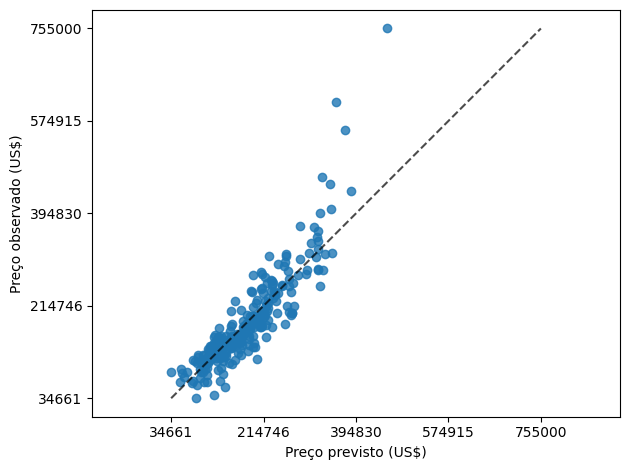

In [414]:
# Salvamos a tabela sem gravar o índice como uma coluna extra.
test_results.to_csv("house-predictions.csv", index=False)

PredictionErrorDisplay.from_predictions(
    test["SalePrice"],
    test_predictions,
    kind="actual_vs_predicted",
    random_state=42,
)

plt.xlabel("Preço previsto (US$)")
plt.ylabel("Preço observado (US$)")

plt.tight_layout()

plt.show()

## Organizar o que vocês fizeram

Deixem o notebook com o código executado, as consultas que montaram e os resultados dos experimentos que escolheram fazer. Organizem as saídas para dar para acompanhar o caminho sem procurar números em uma célula enorme.

Nas análises, comentem o que os dados mostraram e como isso influenciou uma decisão. Se uma tentativa piorou ou quase não mudou o resultado, deixem isso registrado também. Uma explicação curta junto da tabela ou do gráfico já ajuda a sustentar a conclusão.

A ideia da entrega é conseguir acompanhar o raciocínio de vocês e reproduzir os resultados.